# Откриване на PortScan, DDoS и BruteForce с машинно обучение (CSE-CIC-IDS2018 и CIC-IDS2017)

**Курсов проект:** Експериментално изследване на откриване на проникване в мрежов трафик на център за данни, базирано на машинно обучение.

Ноутбукът минава през цялото изследване и генерира всички диаграми в презентацията. Използват се само реални записи от два публични набора на Canadian Institute for Cybersecurity: CSE-CIC-IDS2018 (DDoS и BruteForce, уловени в инфраструктура на Amazon Web Services) и коригираната версия на CIC-IDS2017 (PortScan). Синтетични данни няма.

| Част | Съдържание |
|---|---|
| 0 | Настройка на средата (локално или в Google Colab) |
| 1 | Зареждане и почистване на реалните CSV файлове |
| 2 | Изследване на данните: класове, разделимост, проекции |
| 3 | Предварителна обработка: филтър, подбор на признаци, стандартизация |
| 4 | Деветте модела: избор на хиперпараметри с правилото „една стандартна грешка“ |
| 5 | Оперативна фаза: TP, TN, FP, FN, Accuracy, Precision, Recall, F1, Specificity |
| 6 | Преобучение, bootstrap и тест на McNemar |
| 7 | Контролни експерименти E1–E5 и анализи A3–A8 |
| 8 | Предварително изследване върху CICIoT2023 и изображение за титулната страница |

Моделите и таблиците в `results/` се създават от `python run_all.py`. Ноутбукът ги чете, проверява ключови числа срещу данните и рисува диаграмите в `presentation/figures/`.

## 0. Настройка на средата

**В Google Colab:** качете папката на хранилището `ml-ids-cicids2018` (с изтеглените CSV файлове в `data/raw/` и `data/raw_cicids2017/`) в Google Drive и изпълнете клетката.

**Локално:** ноутбукът се стартира от папката `notebooks/` на хранилището.

Суровите данни се изтеглят от публичното хранилище на CSE-CIC-IDS2018 в AWS S3 и от страницата на коригирания CIC-IDS2017 (вж. `data/README.md`).

In [1]:
import sys, os, json, time, warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO = Path("/content/drive/MyDrive/ml-ids-cicids2018")
    os.system("pip -q install scikit-learn joblib xgboost")
else:
    REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(REPO))
os.chdir(REPO)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib import font_manager
from sklearn.metrics import roc_curve

from src import config as C
from src.registry import ATTACKS, ALGORITHMS
from src.preprocess import load_raw, clean, build_task
from src.evaluate import scores_of

RES = REPO / "results"
FIG = REPO / "presentation" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
for old in FIG.glob("p*.png"):
    old.unlink()
ATT = list(ATTACKS)              # PortScan, DDoS, BruteForce
HARD = "PortScan"                 # атаката, показана подробно в диаграмите за един модел
ALG = list(ALGORITHMS)           # RF, SVM, XGB
print("Хранилище:", REPO)
print("Атаки:", ATT, "| Алгоритми:", ALG)

Хранилище: .
Атаки: ['PortScan', 'DDoS', 'BruteForce'] | Алгоритми: ['RF', 'SVM', 'XGB']


### Стил на диаграмите

Едни и същи цветове навсякъде: **сиво** е нормалният трафик (по-светло за CIC-IDS2017), **червено** е DDoS, **виолетово** е BruteForce, **кехлибарено** е PortScan. При сравнение на алгоритмите **синьо** е Random Forest, **тюркоазено** е SVM, а **оранжево** е XGBoost.

In [2]:
INK, MUTED, GRID = "#14213D", "#3F4858", "#E3E7EE"
BENIGN, BENIGN17, DDOS, BRUTE, SCAN = "#8D99AE", "#B9C2D0", "#D64545", "#7A4FB5", "#E69B23"
ALGO_C = {"RF": "#1D5FA8", "SVM": "#14A38B", "XGB": "#D9731A"}
ALGO_N = {"RF": "Random Forest", "SVM": "SVM (RBF)", "XGB": "XGBoost"}
ATT_C = {"DDoS": DDOS, "BruteForce": BRUTE, "PortScan": SCAN}
ATT_N = {"DDoS": "DDoS", "BruteForce": "BruteForce", "PortScan": "PortScan"}
ATT_DS = {a: ATTACKS[a].dataset for a in ATT}      # набор на всяка атака
GRP_C = {"Нормален": BENIGN, "Нормален 2017": BENIGN17, **ATT_C}
GROUPS0 = ["Нормален 2017", "PortScan", "Нормален", "DDoS", "BruteForce"]
GRP_N = {"Нормален": "Нормален трафик (2018)", "Нормален 2017": "Нормален трафик (2017)", **ATT_N}

fams = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Times New Roman", "Liberation Serif", "DejaVu Serif"] if f in fams), "DejaVu Serif")
plt.rcParams.update({
    "font.family": FONT, "font.size": 18, "font.style": "normal",
    "axes.titlesize": 19, "axes.titleweight": "normal", "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelsize": 18, "axes.labelcolor": INK, "axes.edgecolor": "#C5CCD6", "axes.linewidth": 0.9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.9,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 17, "ytick.labelsize": 17,
    "legend.frameon": False, "legend.fontsize": 16.5, "figure.dpi": 110, "savefig.dpi": 220,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.08, "mathtext.default": "regular",
})


def fmt_int(n):
    return f"{int(round(n)):,}".replace(",", " ")


def fmt_pct(x, k=1):
    return f"{x * 100:.{k}f}".replace(".", ",") + "%"


def PCT(decimals=0):
    """Проценти с десетична запетая (български запис)."""
    return FuncFormatter(lambda v, _: f"{v * 100:.{decimals}f}".replace(".", ",") + "%")


INTF = FuncFormatter(lambda v, _: fmt_int(v))


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", facecolor="white")
    plt.show()
    plt.close(fig)


def legend_below(fig, handles, labels, ncol=4, y=-0.01, fontsize=16):
    """Обща легенда под графиката, извън областта с данни (не се застъпва с тях)."""
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False,
               fontsize=fontsize, handlelength=2.2, columnspacing=1.8)


def group_of(label):
    if label == C.BENIGN_LABEL:
        return "Нормален"
    if label == C.BENIGN_LABEL_2017:
        return "Нормален 2017"
    return next(a for a, spec in ATTACKS.items() if spec(label))

## 1. Зареждане и почистване на реалните данни

Четат се шест дневни CSV файла. От CSE-CIC-IDS2018: сряда 14.02.2018 (FTP и SSH BruteForce), сряда 21.02.2018 (DDoS с HOIC и LOIC-UDP) и петък 02.03.2018 (само нормален трафик). От коригирания CIC-IDS2017: петък 07.07.2017 (PortScan) и понеделник 03.07 и сряда 05.07.2017 (само нормален трафик). Колоните на CIC-IDS2017 се преименуват към имената от CSE-CIC-IDS2018. Колоните `Timestamp` и `Dst Port` се премахват, защото описват момента и мястото на експеримента, а не поведението на потока. След това се махат записите с NaN/Inf и пълните дубликати.

In [3]:
t0 = time.time()
raw, load_stats = load_raw()
df, clean_stats = clean(raw)
del raw
print(f"Прочетени записи: {fmt_int(load_stats['rows_read_total'])} от {load_stats['files']} файла за {time.time() - t0:.0f} s")
print(f"След почистване: {fmt_int(len(df))} записа, {df.shape[1] - 1} признака")
ref = json.load(open(RES / "dataset_stats.json"))
assert ref["clean"]["rows_after"] == len(df), "броят записи се различава от записания в results/"
lbl = df[C.LABEL_COLUMN].astype(str).to_numpy()
grp = np.array([group_of(x) for x in pd.unique(lbl)], dtype=object)
grp = pd.Series(grp, index=pd.unique(lbl)).reindex(lbl).to_numpy()
print(pd.Series(grp).value_counts())

Прочетени записи: 4 561 547 от 6 файла за 51 s
След почистване: 2 662 013 записа, 77 признака


Нормален         1472334
Нормален 2017     893304
DDoS              200591
BruteForce         94101
PortScan            1683
Name: count, dtype: int64


### Диаграма 1. Записи по клас и ефект на почистването

Вляво е броят записи по етикет преди и след почистването (логаритмична скала). Вдясно е делът на премахнатите записи (NaN/Inf и дубликати). При FTP BruteForce от около 193 хиляди записа остават 53 уникални, а при PortScan от около 159 хиляди остават под 2 хиляди: всеки опит за вход и всяка проба на скенера генерират почти идентичен поток. Показани са само използваните етикети.

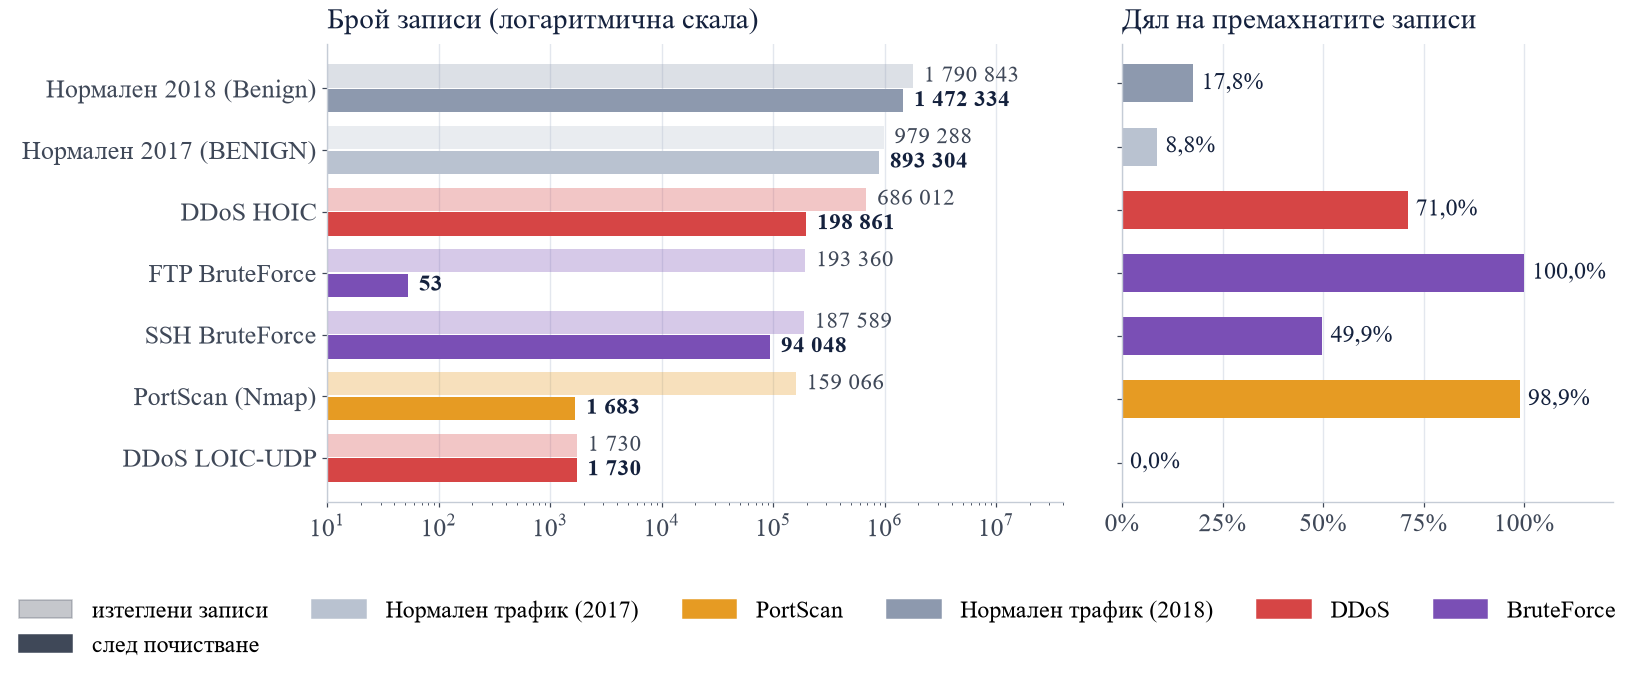

In [4]:
LBL_N = {"Benign": "Нормален 2018 (Benign)", C.BENIGN_LABEL_2017: "Нормален 2017 (BENIGN)", "DDOS attack-HOIC": "DDoS HOIC",
         "DDOS attack-LOIC-UDP": "DDoS LOIC-UDP", "PortScan": "PortScan (Nmap)", "FTP-BruteForce": "FTP BruteForce",
         "SSH-Bruteforce": "SSH BruteForce"}
orig = pd.Series(load_stats["original_class_counts"])
orig = orig[[k for k in orig.index if k in LBL_N]]          # само използваните етикети
after = pd.Series(clean_stats["class_counts_after_cleaning"]).reindex(orig.index).fillna(0)
order = orig.sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
yy = np.arange(len(order))
cols = [GRP_C[group_of(k)] for k in order]
ax.barh(yy + 0.2, orig[order], height=0.38, color=cols, alpha=0.3)
ax.barh(yy - 0.2, after[order], height=0.38, color=cols)
for y_, k in zip(yy, order):
    ax.text(orig[k] * 1.25, y_ + 0.2, fmt_int(orig[k]), va="center", fontsize=15, color=MUTED)
    ax.text(max(after[k], 1) * 1.25, y_ - 0.2, fmt_int(after[k]), va="center", fontsize=15, color=INK, weight="bold")
ax.set_yticks(yy, [LBL_N[k] for k in order]); ax.set_xscale("log"); ax.set_xlim(10, 4e7)
ax.set_title("Брой записи (логаритмична скала)"); ax.grid(axis="y", visible=False)
ax = axes[1]
share = 1 - after[order] / orig[order]
ax.barh(yy, share, color=cols, height=0.6)
for y_, v in zip(yy, share):
    ax.text(v + 0.02, y_, fmt_pct(v, 1), va="center", fontsize=15.5, color=INK)
ax.set_yticks(yy, [""] * len(yy)); ax.set_xlim(0, 1.22); ax.xaxis.set_major_formatter(PCT())
ax.set_title("Дял на премахнатите записи"); ax.grid(axis="y", visible=False)
fig.tight_layout(w_pad=1.5)
legend_below(fig, [Patch(color=MUTED, alpha=0.3), Patch(color=MUTED)] + [Patch(color=GRP_C[g]) for g in GROUPS0],
             ["изтеглени записи", "след почистване"] + [GRP_N[g] for g in GROUPS0], ncol=6)
save(fig, "p01_class_counts")

## 2. Изследване на данните

### Формиране на задачите

За всяка атака се строи балансирана бинарна задача: всички уникални записи на атаката (до 100 000) срещу същия брой случайни нормални записи от същия набор. Записите с противоречив етикет се премахват. Данните се делят стратифицирано 70/30.

In [5]:
tasks = {a: build_task(df, a, load_stats["original_class_counts"]) for a in ATT}
for a, t in tasks.items():
    ref_t = json.load(open(RES / "task_stats.json"))[a]
    assert ref_t["test_rows"] == len(t["X_test"]), a
    print(f"{a:11s} обучение {fmt_int(len(t['X_train']))}  тест {fmt_int(len(t['X_test']))}")

PortScan    обучение 2 354  тест 1 010
DDoS        обучение 140 000  тест 60 000
BruteForce  обучение 131 731  тест 56 457


### Диаграма 2. Профил на атаките

Медиана (точка) и интерквартилен размах (лента) на четири признака за по 20 000 реални записа от всеки вид трафик. DDoS (HOIC) праща много пакети в кратки потоци; BruteForce има по-дълги потоци с почти постоянен брой пакети; пробата на PortScan е най-краткият поток: един пакет от скенера и един отговор.

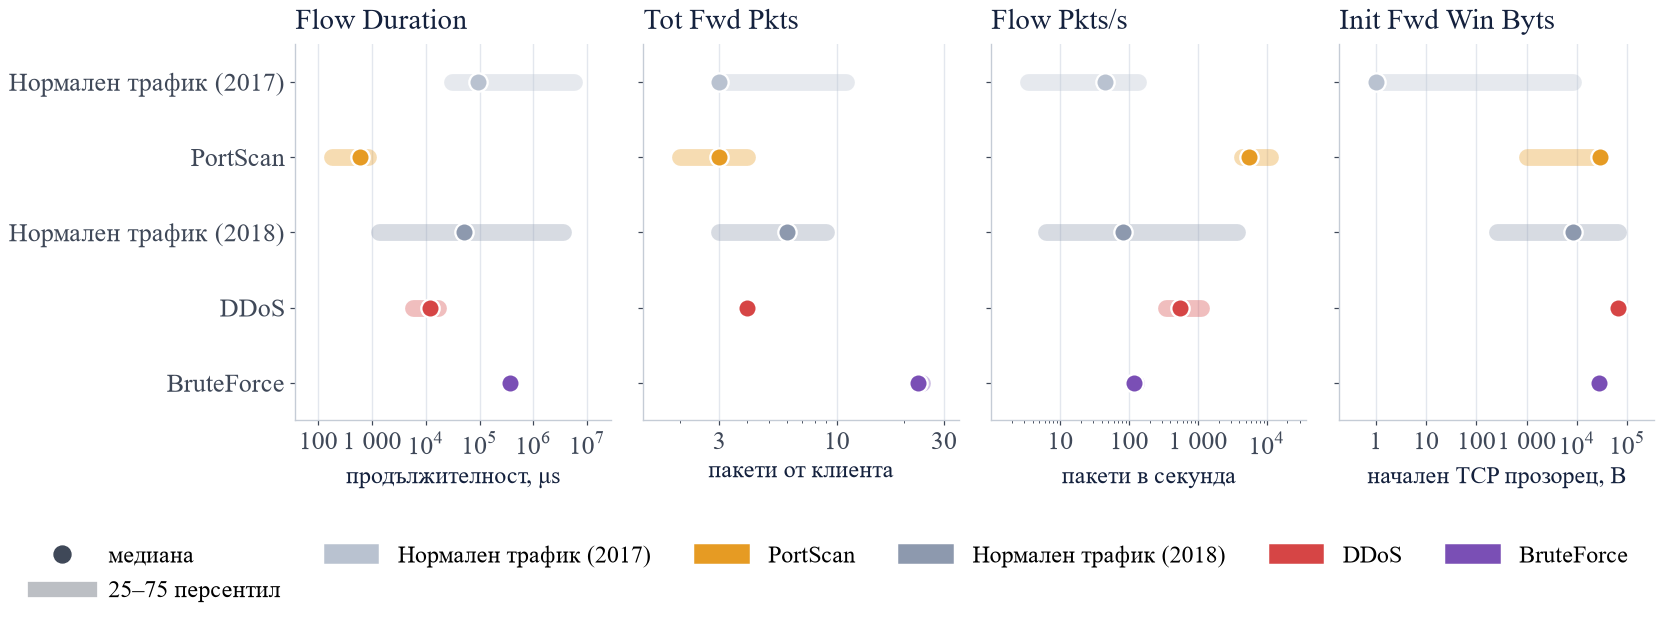

In [6]:
rng = np.random.default_rng(7)
GROUPS = GROUPS0
samp_idx = np.concatenate([rng.choice(np.where(grp == g)[0], min(20_000, (grp == g).sum()), replace=False) for g in GROUPS])
S = df.iloc[samp_idx].copy(); S["група"] = grp[samp_idx]
show = ["Flow Duration", "Tot Fwd Pkts", "Flow Pkts/s", "Init Fwd Win Byts"]
units = {"Flow Duration": "продължителност, μs", "Tot Fwd Pkts": "пакети от клиента", "Flow Pkts/s": "пакети в секунда", "Init Fwd Win Byts": "начален TCP прозорец, B"}
fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.9), sharey=True)
for ax, f in zip(axes, show):
    for k, g in enumerate(GROUPS):
        v = S.loc[S["група"] == g, f].astype(float).clip(lower=0) + 1
        q1, q2, q3 = np.quantile(v, [0.25, 0.5, 0.75])
        ax.plot([q1, q3], [k, k], color=GRP_C[g], lw=11, alpha=0.35, solid_capstyle="round")
        ax.plot(q2, k, "o", color=GRP_C[g], ms=12, mec="white", mew=1.5)
    ax.set_xscale("log"); ax.set_title(f); ax.set_xlabel(units[f], fontsize=15.5); ax.grid(axis="y", visible=False); ax.margins(x=0.15)
    ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1.0,) if np.ptp(ax.get_xlim()) > 50 else (1.0, 3.0), numticks=8)); ax.xaxis.set_minor_formatter(NullFormatter())
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_int(v) if v < 1e4 else f"$10^{{{int(round(np.log10(v)))}}}$" if abs(np.log10(v) - round(np.log10(v))) < 1e-6 else ""))
axes[0].set_yticks(range(len(GROUPS)), [GRP_N[g] for g in GROUPS]); axes[0].invert_yaxis(); axes[0].set_ylim(len(GROUPS) - 0.5, -0.5)
fig.tight_layout(w_pad=1.0)
legend_below(fig, [Line2D([], [], color=MUTED, marker="o", ls="", ms=11), Line2D([], [], color=MUTED, lw=10, alpha=0.35)] + [Patch(color=GRP_C[g]) for g in GROUPS],
             ["медиана", "25–75 персентил"] + [GRP_N[g] for g in GROUPS], ncol=6)
save(fig, "p03_attack_profile")

### Диаграма 3. Разделимост на признаците (тест на Колмогоров–Смирнов)

KS разстоянието $D$ е максималната разлика между емпиричните функции на разпределение на признака за атаката и за нормалния трафик. $D=1$ означава, че един праг разделя класовете напълно. Пунктирът е средното на десетте признака.

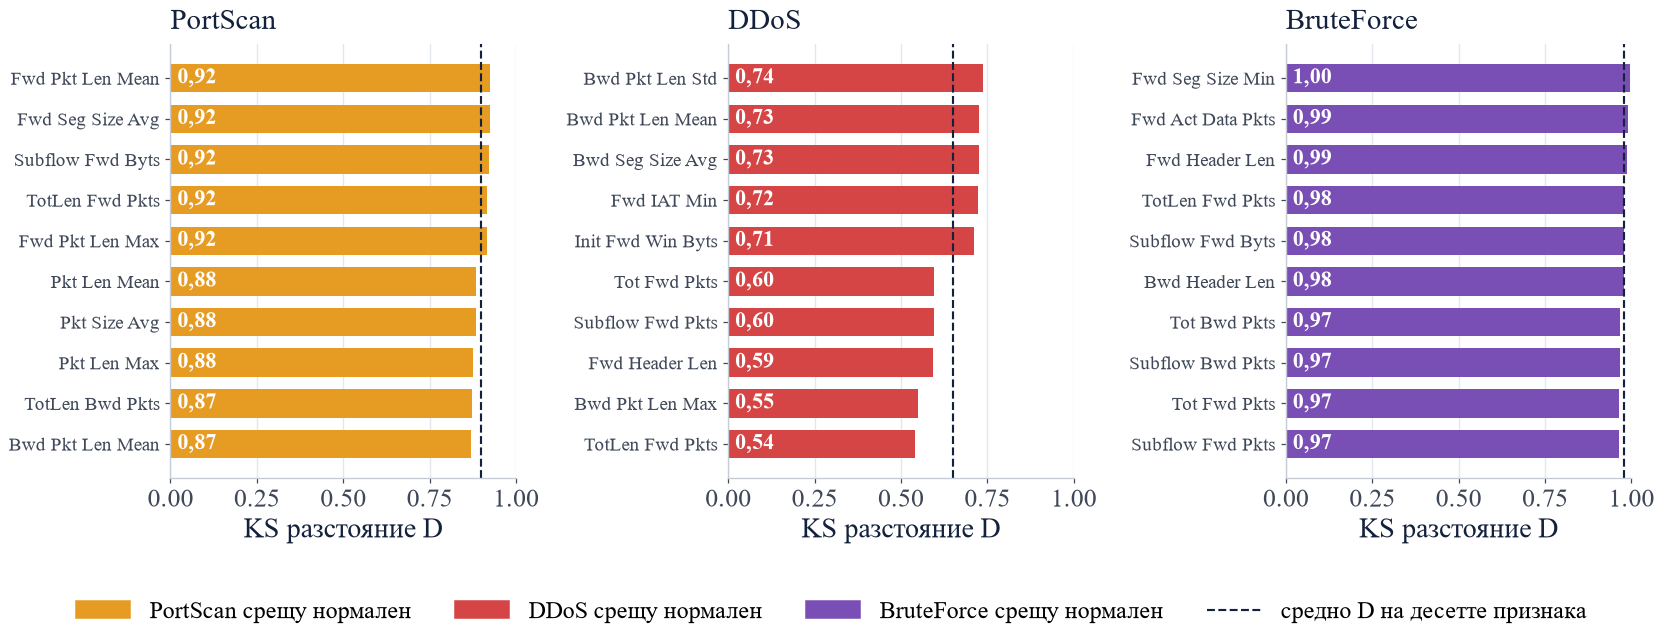

In [7]:
KSdf = pd.read_csv(RES / "ks_separability.csv")
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.4))
for ax, a in zip(axes, ATT):
    top = KSdf[KSdf.attack == a].nlargest(10, "KS_D").iloc[::-1]
    ax.barh(top.feature, top.KS_D, color=ATT_C[a], height=0.7)
    for y_, v in enumerate(top.KS_D):
        ax.text(0.02, y_, f"{v:.2f}".replace(".", ","), va="center", ha="left", fontsize=14.5, color="white", weight="bold")
    ax.axvline(top.KS_D.mean(), color=INK, ls="--", lw=1.4)
    ax.set_xlim(0, 1.0); ax.set_title(ATT_N[a]); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=12.5)
    ax.set_xlabel("KS разстояние D")
fig.tight_layout(w_pad=1.0)
legend_below(fig, [Patch(color=ATT_C[a]) for a in ATT] + [Line2D([], [], color=INK, ls="--", lw=1.4)],
             [f"{ATT_N[a]} срещу нормален" for a in ATT] + ["средно D на десетте признака"], ncol=4)
save(fig, "p04_ks_separability")

### Диаграма 4. Двумерни проекции (t-SNE)

Проекциите са изчислени в `run_all.py` върху до 1500 реални записа от всеки клас. Отделни, добре оформени групи показват, че класовете са геометрично разделими.

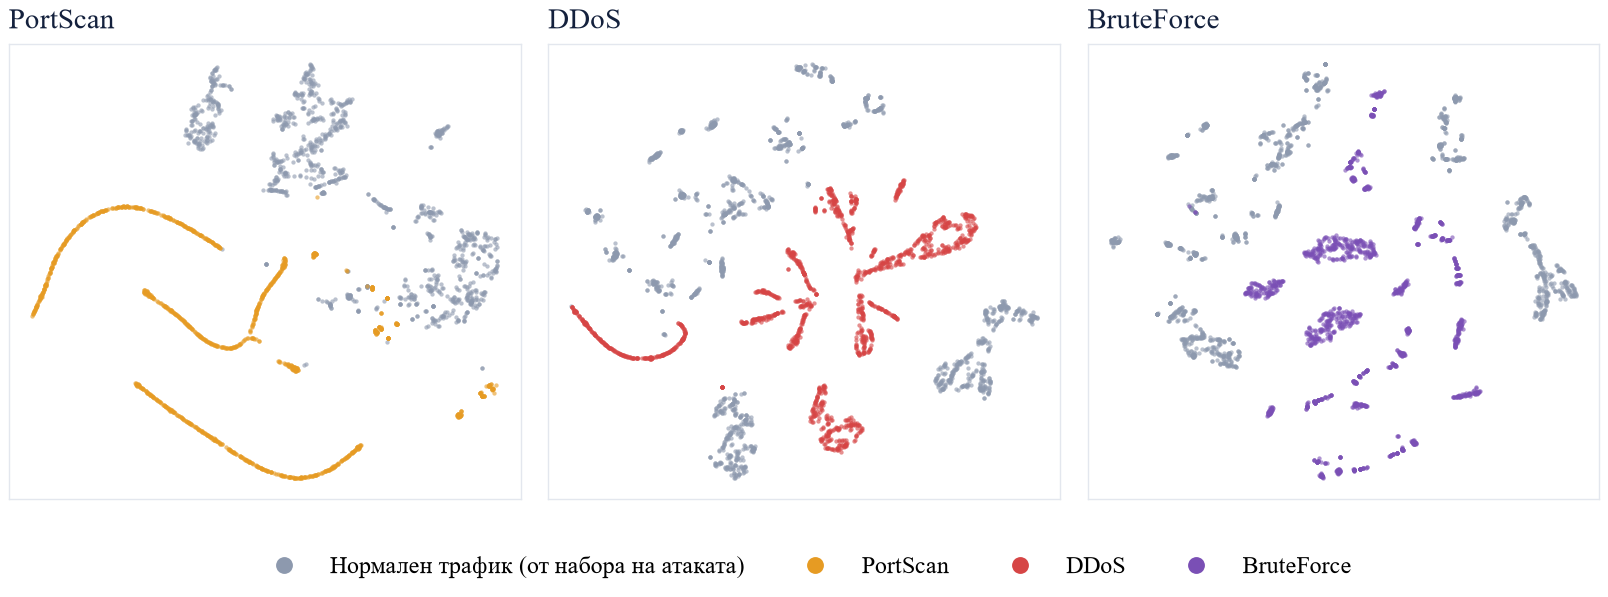

In [8]:
P = pd.read_csv(RES / "projections_2d.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 5.0))
for ax, a in zip(axes, ATT):
    d = P[P.attack == a]
    for yv, c in [(0, BENIGN), (1, ATT_C[a])]:
        q = d[d.y == yv]
        ax.scatter(q.tsne1, q.tsne2, s=8, color=c, alpha=0.6, linewidths=0)
    ax.set_title(ATT_N[a]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color(GRID)
fig.tight_layout(w_pad=1.0)
legend_below(fig, [Line2D([], [], color=GRP_C[g], marker="o", ls="", ms=10) for g in ["Нормален"] + ATT],
             ["Нормален трафик (от набора на атаката)"] + [ATT_N[a] for a in ATT], ncol=4)
save(fig, "p06_projection")

## 3. Предварителна обработка и редукция на вектора на признаците

Конвейерът е `FeatureFilter → ImportanceSelector → StandardScaler → класификатор`. Филтърът маха константните признаци, подборът оставя 20-те признака с най-голяма важност (gain) в помощен XGBoost модел, обучен само върху обучаващите данни. PCA е контролният вариант (E5).

### Диаграма 5. Брой признаци и важност на избраните признаци

Входни признаци: 77 | след филтъра: 71 | избрани: 20


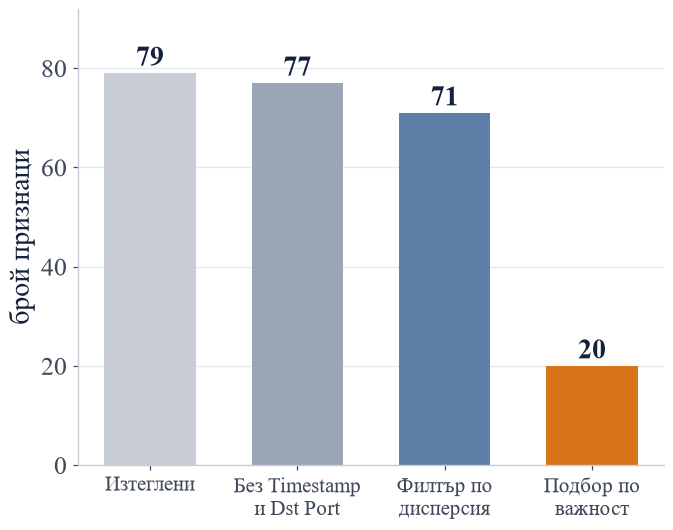

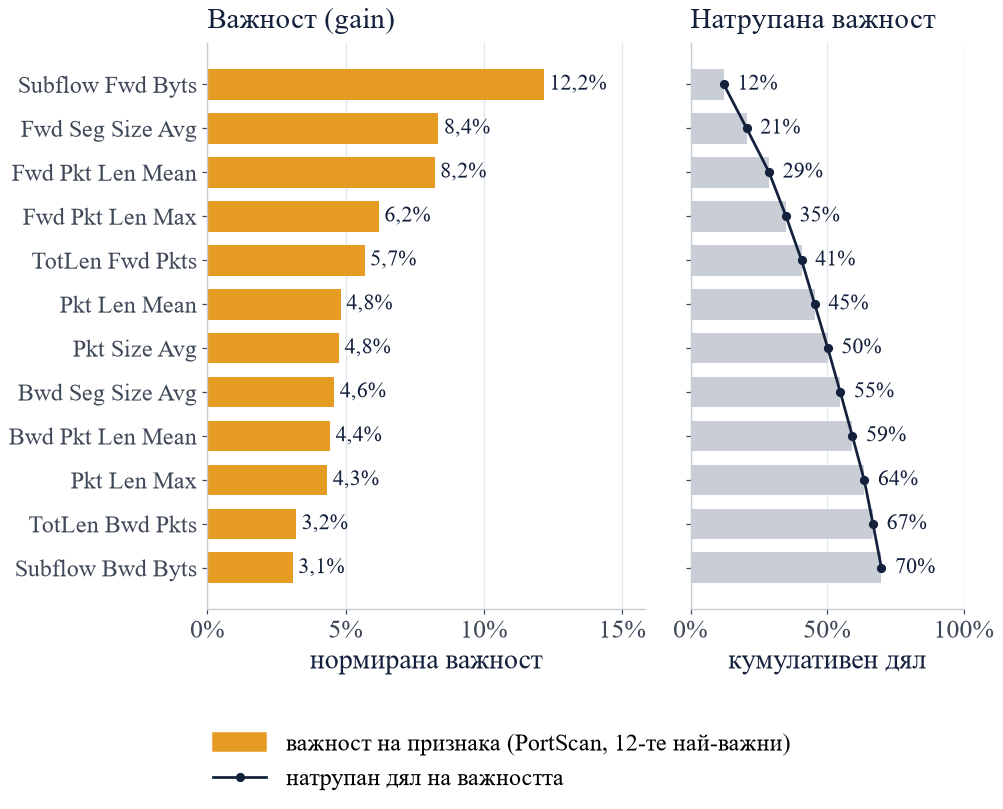

In [9]:
RED = json.load(open(RES / "reduction.json"))
r0 = RED[f"XGB_{HARD}"]
print("Входни признаци:", r0["n_features_in"], "| след филтъра:", r0["n_features_after_filter"], "| избрани:", r0["n_reduced"])
fig, ax = plt.subplots(figsize=(6.5, 5.2))
steps = [("Изтеглени", 79), ("Без Timestamp\nи Dst Port", r0["n_features_in"]), ("Филтър по\nдисперсия", r0["n_features_after_filter"]), ("Подбор по\nважност", r0["n_reduced"])]
sc = ["#C9CED6", "#9AA6B8", "#5F7FA8", ALGO_C["XGB"]]
ax.bar(range(4), [v for _, v in steps], color=sc, width=0.62)
for k, (_, v) in enumerate(steps):
    ax.text(k, v + 1.5, str(v), ha="center", fontsize=18.5, color=INK, weight="bold")
ax.set_xticks(range(4), [s for s, _ in steps], fontsize=14); ax.set_ylim(0, 92); ax.set_ylabel("брой признаци")
ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "p07_dimensions")

imp_all = pd.read_csv(RES / f"feature_importance_{HARD}.csv", index_col=0).iloc[:, 0].sort_values(ascending=False)
imp = imp_all.head(12)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(9.5, 6.6), sharey=True, gridspec_kw={"width_ratios": [1.6, 1]})
yy = np.arange(len(imp))[::-1]
ax.barh(yy, imp.values, color=SCAN, height=0.7)
for y_, v in zip(yy, imp.values):
    ax.text(v + 0.002, y_, fmt_pct(v, 1), va="center", fontsize=14.5, color=INK)
ax.set_yticks(yy, imp.index, fontsize=15.5); ax.xaxis.set_major_formatter(PCT()); ax.set_xlim(0, imp.max() * 1.3)
ax.set_xlabel("нормирана важност"); ax.set_title("Важност (gain)"); ax.grid(axis="y", visible=False)
cum = imp_all.cumsum().head(12).values
ax2.barh(yy, cum, color="#C9CED6", height=0.7)
ax2.plot(cum, yy, "-o", color=INK, lw=1.8, ms=5)
for y_, v in zip(yy, cum):
    ax2.text(v + 0.05, y_, fmt_pct(v, 0), va="center", fontsize=14.5, color=INK)
ax2.set_xlim(0, 1.0); ax2.xaxis.set_major_formatter(PCT()); ax2.set_xlabel("кумулативен дял"); ax2.set_title("Натрупана важност"); ax2.grid(axis="y", visible=False)
fig.tight_layout(w_pad=1.0)
legend_below(fig, [Patch(color=SCAN), Line2D([], [], color=INK, marker="o", lw=1.8, ms=5)],
             [f"важност на признака ({HARD}, 12-те най-важни)", "натрупан дял на важността"], ncol=1)
save(fig, "p08_selection")

## 4. Избор на хиперпараметри: правило „една стандартна грешка“

За всяка конфигурация се изчисляват среден F1 и стандартна грешка по петте фолда. Избира се най-простата конфигурация в рамките на една стандартна грешка от най-добрата. Диаграмата показва това за PortScan, където разликите между конфигурациите са най-големи.

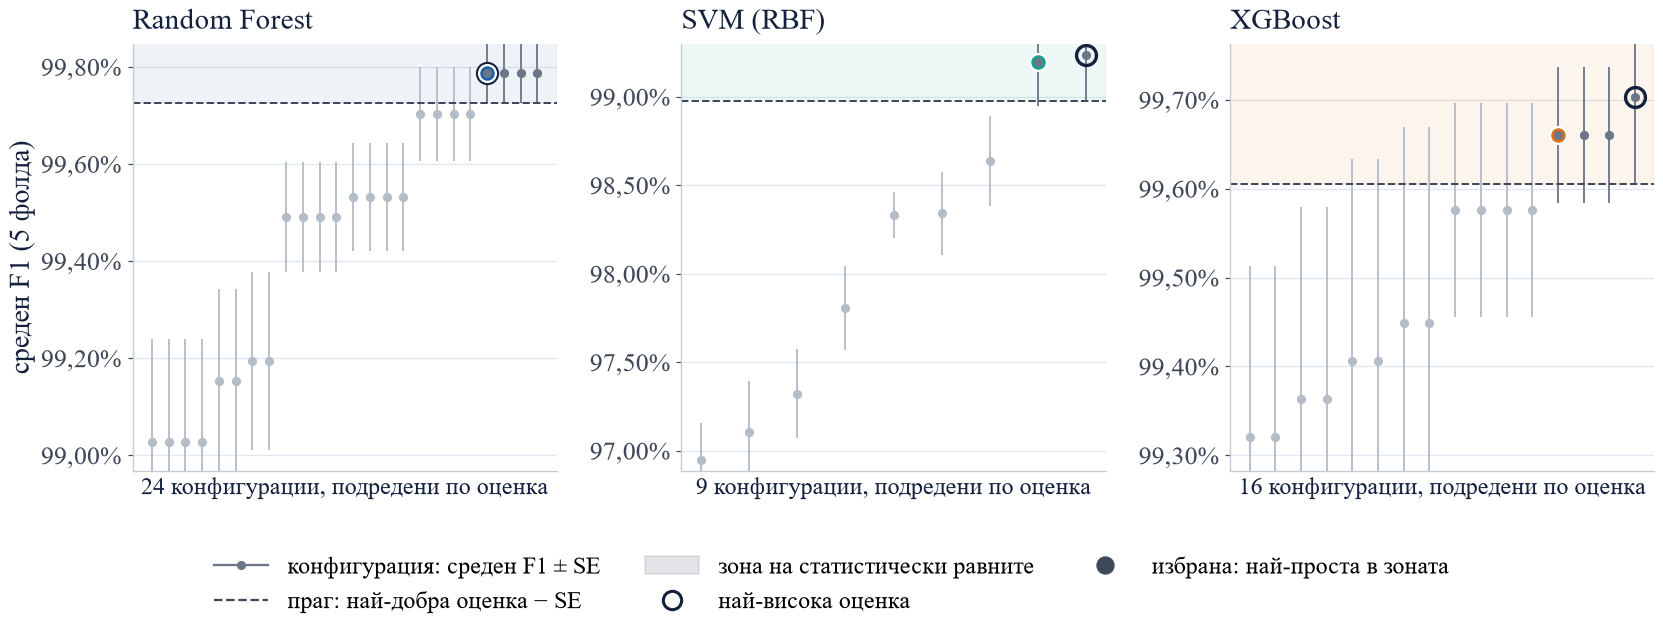

RF {'clf__max_depth': 25, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 200}
SVM {'clf__C': 100, 'clf__gamma': 'scale'}
XGB {'clf__learning_rate': 0.03, 'clf__max_depth': 6, 'clf__min_child_weight': 1, 'clf__n_estimators': 300}


In [10]:
CV = json.load(open(RES / "cv_summary.json"))
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0))
for ax, g in zip(axes, ALG):
    cv = pd.read_csv(RES / f"cv_{g}_{HARD}.csv").sort_values("mean_test_score").reset_index(drop=True)
    se = cv.std_test_score / np.sqrt(C.CV_FOLDS)
    x = np.arange(len(cv))
    thr = cv.one_se_threshold.iloc[0]
    ok = cv.mean_test_score >= thr
    ax.axhspan(thr, 1.1, color=ALGO_C[g], alpha=0.07)
    ax.errorbar(x[~ok], cv.mean_test_score[~ok], yerr=se[~ok], fmt="o", color="#B4BCC8", ms=5, lw=1.2)
    ax.errorbar(x[ok], cv.mean_test_score[ok], yerr=se[ok], fmt="o", color="#6B7688", ms=5, lw=1.2)
    ax.axhline(thr, color=MUTED, ls="--", lw=1.3)
    b = cv.index[cv.rank_test_score == 1][0]; s_ = cv.index[cv.selected][0]
    ax.plot(x[b], cv.mean_test_score[b], "o", color=INK, ms=13, mfc="none", mew=2.2)
    ax.plot(x[s_], cv.mean_test_score[s_], "o", color=ALGO_C[g], ms=11, mec="white", mew=1.5)
    lo = cv.mean_test_score.quantile(0.1) if g != "SVM" else cv.mean_test_score.min()
    ax.set_ylim(lo - 0.0006, min(cv.mean_test_score.max() + 0.0006, 1.00005))
    ax.yaxis.set_major_formatter(PCT(2)); ax.set_xticks([])
    ax.set_xlabel(f"{len(cv)} конфигурации, подредени по оценка", fontsize=15.5); ax.set_title(ALGO_N[g])
axes[0].set_ylabel("среден F1 (5 фолда)")
fig.tight_layout(w_pad=1.2)
legend_below(fig, [Line2D([], [], color="#6B7688", marker="o", ls="-", ms=5), Line2D([], [], color=MUTED, ls="--"), Patch(color=MUTED, alpha=0.15),
                   Line2D([], [], color=INK, marker="o", ls="", ms=12, mfc="none", mew=2), Line2D([], [], color=MUTED, marker="o", ls="", ms=11)],
             ["конфигурация: среден F1 ± SE", "праг: най-добра оценка − SE", "зона на статистически равните", "най-висока оценка", "избрана: най-проста в зоната"], ncol=3)
save(fig, "p09_one_se")
for g in ALG:
    print(g, CV[f"{g}_{HARD}"]["best_params"])

### Диаграма 6б. Чувствителност към хиперпараметрите (PortScan)

Среден F1 от кръстосаната валидация за всяка комбинация от хиперпараметри (при RF и XGBoost е осреднен по броя дървета). Рамката е конфигурацията, избрана с правилото 1-SE.

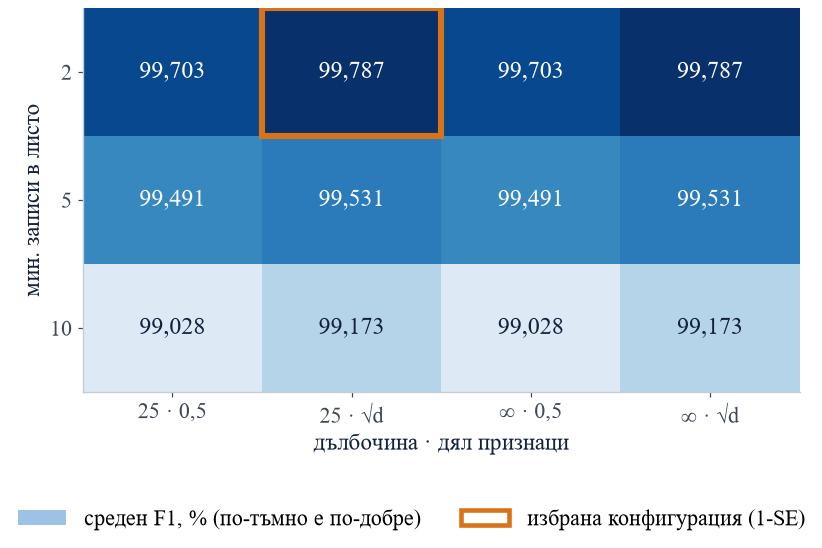

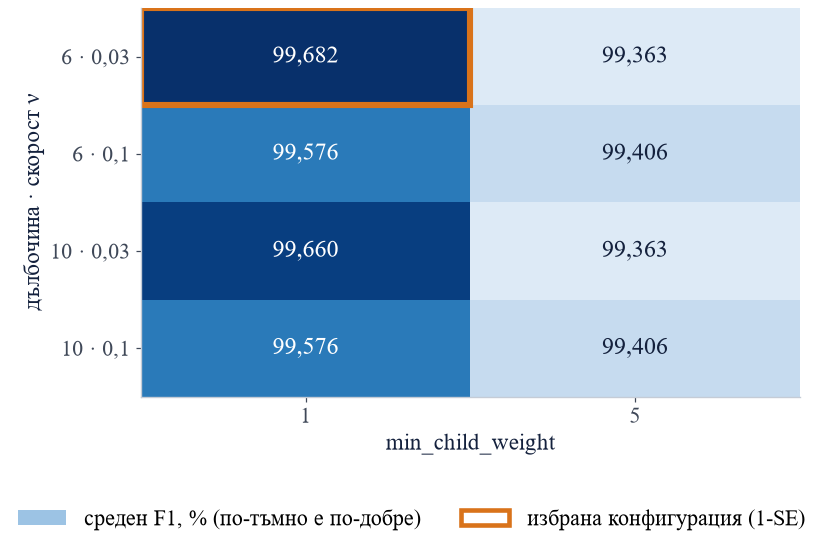

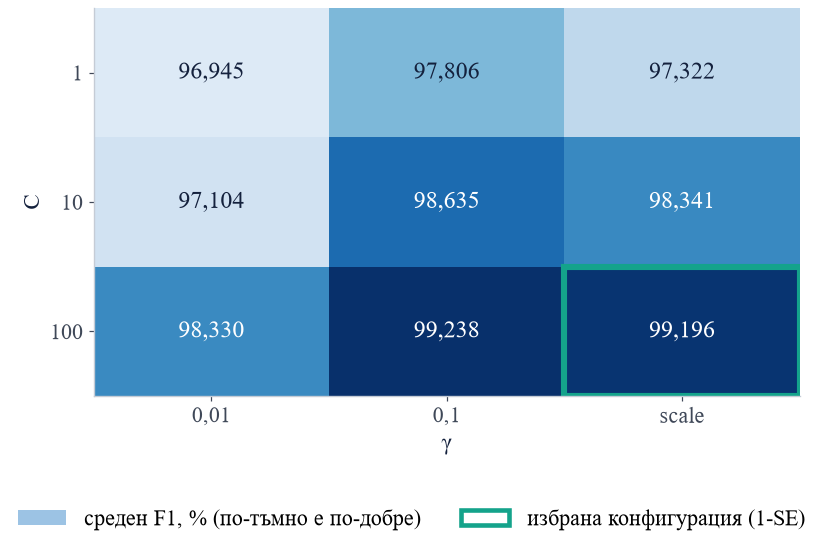

In [11]:
def hp_heat(g, rows, cols, rname, cname, fmt_r, fmt_c, avg=None):
    cv = pd.read_csv(RES / f"cv_{g}_{HARD}.csv")
    for c in cv.columns:
        if c.startswith("param_"):
            cv[c] = cv[c].fillna("∞").astype(str)
    cv["_r"] = cv[rows].astype(str).agg(" · ".join, axis=1) if isinstance(rows, list) else cv[rows]
    cv["_c"] = cv[cols].astype(str).agg(" · ".join, axis=1) if isinstance(cols, list) else cv[cols]
    T_ = cv.groupby(["_r", "_c"]).mean_test_score.mean().unstack()
    key = lambda v: [float(x) if x.replace(".", "").isdigit() else (1e9 if x == "∞" else 1e10) for x in v.split(" · ")]
    T_ = T_.loc[sorted(T_.index, key=key), sorted(T_.columns, key=key)]
    sel = cv[cv.selected].iloc[0]
    fig, ax = plt.subplots(figsize=(7.6, 4.6))
    im = ax.imshow(T_.values, cmap="Blues", aspect="auto", vmin=T_.values.min() - (T_.values.max() - T_.values.min()) * 0.15)
    for (i, j), v in np.ndenumerate(T_.values):
        ax.text(j, i, f"{v * 100:.3f}".replace(".", ","), ha="center", va="center", fontsize=16,
                color="white" if v > T_.values.min() + (T_.values.max() - T_.values.min()) * 0.55 else INK)
    i0, j0 = list(T_.index).index(sel["_r"]), list(T_.columns).index(sel["_c"])
    ax.add_patch(plt.Rectangle((j0 - 0.5, i0 - 0.5), 1, 1, fill=False, ec=ALGO_C[g] if g != "RF" else "#D9731A", lw=4))
    ax.set_xticks(range(T_.shape[1]), [fmt_c(c) for c in T_.columns], fontsize=14.5); ax.set_yticks(range(T_.shape[0]), [fmt_r(r) for r in T_.index], fontsize=14.5)
    ax.set_xlabel(cname, fontsize=15); ax.set_ylabel(rname, fontsize=15); ax.grid(False)
    fig.tight_layout()
    legend_below(fig, [Patch(facecolor="#9CC3E4"), Patch(fill=False, ec=ALGO_C[g] if g != "RF" else "#D9731A", lw=3)],
                 ["среден F1, % (по-тъмно е по-добре)", "избрана конфигурация (1-SE)"], ncol=2, fontsize=14.5)
    save(fig, f"p09_hp_{g}")

num = lambda x: x.replace(".", ",").replace(",0", "") if x.endswith(".0") else x.replace(".", ",")
hp_heat("RF", "param_clf__min_samples_leaf", ["param_clf__max_depth", "param_clf__max_features"], "мин. записи в листо", "дълбочина · дял признаци",
        num, lambda c: " · ".join(num(x) if x != "sqrt" else "√d" for x in c.split(" · ")))
hp_heat("XGB", ["param_clf__max_depth", "param_clf__learning_rate"], ["param_clf__min_child_weight"], "дълбочина · скорост ν", "min_child_weight",
        lambda r: " · ".join(num(x) for x in r.split(" · ")), num)
hp_heat("SVM", "param_clf__C", "param_clf__gamma", "C", "γ", num, num)

## 5. Оперативна фаза: деветте модела върху невиждани данни

Записаните модели се зареждат от `models/` и класифицират 30% тестови записа. Таблицата съдържа метриките от заданието.

In [12]:
M = pd.read_csv(RES / "metrics.csv")
MET = {(r.attack, r.algo): r for r in M.itertuples()}
models = {(a, g): joblib.load(REPO / "models" / f"{g}_{a}.joblib") for a in ATT for g in ALG}
# проверка: моделите дават същите грешки като в results/metrics.csv
for (a, g), m in models.items():
    t = tasks[a]
    yp = m.predict(t["X_test"])
    fp = int(((yp == 1) & (t["y_test"] == 0)).sum()); fn = int(((yp == 0) & (t["y_test"] == 1)).sum())
    assert (fp, fn) == (MET[(a, g)].FP, MET[(a, g)].FN), (a, g, fp, fn)
print("Матриците на объркване съвпадат с results/metrics.csv")
M[["attack", "algo", "TP", "TN", "FP", "FN", "Accuracy", "Precision", "Sensitivity", "F1", "Specificity"]]

Матриците на объркване съвпадат с results/metrics.csv


,attack,algo,TP,TN,FP,FN,Accuracy,Precision,Sensitivity,F1,Specificity
0,PortScan,RF,504,504,1,1,0.998020,0.998020,0.998020,0.998020,0.998020
1,PortScan,SVM,501,503,2,4,0.994059,0.996024,0.992079,0.994048,0.996040
2,PortScan,XGB,504,503,2,1,0.997030,0.996047,0.998020,0.997033,0.996040
3,DDoS,RF,30000,30000,0,0,1.000000,1.000000,1.000000,1.000000,1.000000
4,DDoS,SVM,29988,29982,18,12,0.999500,0.999400,0.999600,0.999500,0.999400
5,DDoS,XGB,30000,30000,0,0,1.000000,1.000000,1.000000,1.000000,1.000000
6,BruteForce,RF,28227,28229,0,1,0.999982,1.000000,0.999965,0.999982,1.000000
7,BruteForce,SVM,28221,28228,1,7,0.999858,0.999965,0.999752,0.999858,0.999965
8,BruteForce,XGB,28227,28229,0,1,0.999982,1.000000,0.999965,0.999982,1.000000


### Диаграма 6. Метрики и грешки на деветте модела

Вляво: топлинна карта на петте метрики (стойностите са в клетките). Вдясно: брой фалшиви аларми (FP) и пропуснати атаки (FN) на всеки модел.

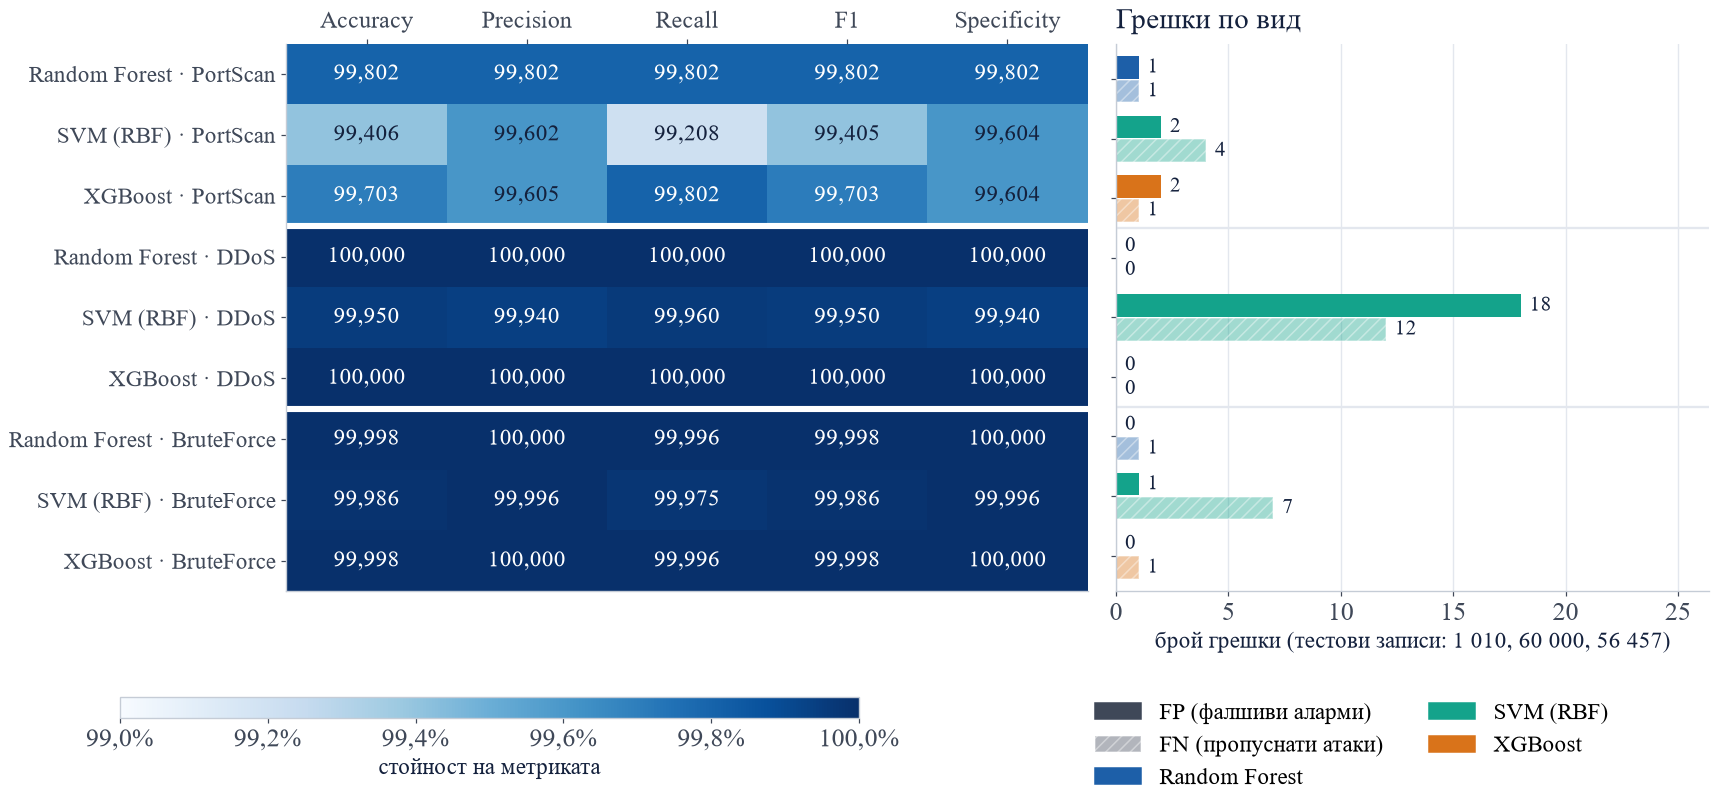

In [13]:
mets = [("Accuracy", "Accuracy"), ("Precision", "Precision"), ("Sensitivity", "Recall"), ("F1", "F1"), ("Specificity", "Specificity")]
ROWS = [(a, g) for a in ATT for g in ALG]
RLAB = [f"{ALGO_N[g]} · {ATT_N[a]}" for a, g in ROWS]
H = np.array([[getattr(MET[k], m) for m, _ in mets] for k in ROWS])
fig, axes = plt.subplots(1, 2, figsize=(16, 6.4), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]
im = ax.imshow(H, cmap="Blues", vmin=min(0.990, H.min() - 0.001), vmax=1.0, aspect="auto")
for (i, j), v in np.ndenumerate(H):
    ax.text(j, i, f"{v * 100:.3f}".replace(".", ","), ha="center", va="center", fontsize=15, color="white" if v > 0.997 else INK)
ax.set_xticks(range(5), [n for _, n in mets], fontsize=15.5); ax.xaxis.tick_top()
ax.set_yticks(range(9), RLAB, fontsize=15); ax.grid(False)
for k in (2.5, 5.5): ax.axhline(k, color="white", lw=4)
ax = axes[1]
yy = np.arange(9)
fp = np.array([MET[k].FP for k in ROWS]); fn = np.array([MET[k].FN for k in ROWS])
ax.barh(yy - 0.2, fp, height=0.38, color=[ALGO_C[g] for _, g in ROWS])
ax.barh(yy + 0.2, fn, height=0.38, color=[ALGO_C[g] for _, g in ROWS], alpha=0.4, hatch="///", edgecolor="white")
for y_, a_, b_ in zip(yy, fp, fn):
    ax.text(a_ + 0.4, y_ - 0.2, str(a_), va="center", fontsize=14, color=INK)
    ax.text(b_ + 0.4, y_ + 0.2, str(b_), va="center", fontsize=14, color=INK)
ax.set_yticks(yy, [""] * 9); ax.set_ylim(8.6, -0.6); ax.set_xlim(0, max(fp.max(), fn.max()) * 1.3 + 3); ax.grid(axis="y", visible=False)
for k in (2.5, 5.5): ax.axhline(k, color=GRID, lw=1.5)
ax.set_xlabel("брой грешки (тестови записи: " + ", ".join(fmt_int(MET[(a, "RF")].n_test) for a in ATT) + ")", fontsize=15); ax.set_title("Грешки по вид")
fig.tight_layout(w_pad=0.8)
cax = fig.add_axes([0.08, -0.05, 0.42, 0.03])
cb = fig.colorbar(im, cax=cax, orientation="horizontal"); cb.ax.xaxis.set_major_formatter(PCT(1)); cb.set_label("стойност на метриката", fontsize=15)
fig.legend(handles=[Patch(color=MUTED), Patch(facecolor=MUTED, alpha=0.4, hatch="///", edgecolor="white")] + [Patch(color=ALGO_C[g]) for g in ALG],
           labels=["FP (фалшиви аларми)", "FN (пропуснати атаки)"] + [ALGO_N[g] for g in ALG],
           loc="upper center", bbox_to_anchor=(0.78, 0.0), ncol=2, frameon=False, fontsize=15)
save(fig, "p11_metrics")

### Диаграма 7. Матрици на объркване

Редовете са истинският клас, колоните са решението на модела. Под всеки брой е делът му от реда. Червено са грешките.

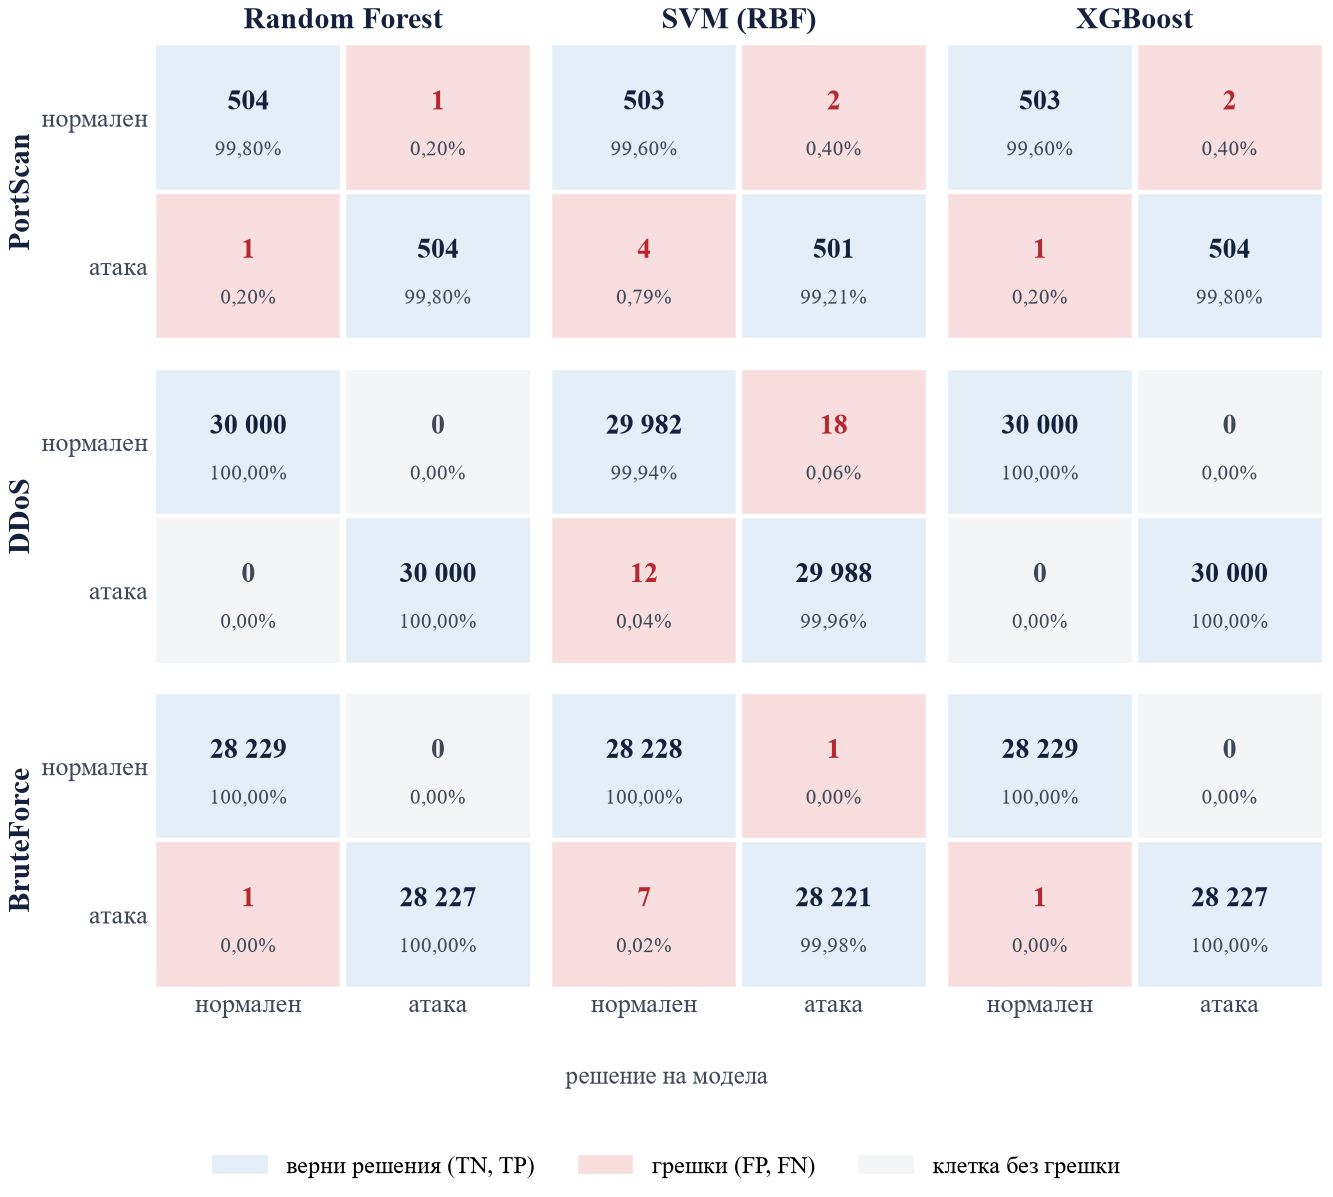

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(12.5, 10.2))
for i, a in enumerate(ATT):
    for j, g in enumerate(ALG):
        ax = axes[i, j]; r = MET[(a, g)]
        cm = np.array([[r.TN, r.FP], [r.FN, r.TP]])
        for (y_, x_), v in np.ndenumerate(cm):
            ok = y_ == x_
            ax.add_patch(plt.Rectangle((x_ - 0.48, y_ - 0.48), 0.96, 0.96, color=("#E4EEF8" if ok else ("#F8DEDE" if v else "#F4F5F7"))))
            ax.text(x_, y_ - 0.1, fmt_int(v), ha="center", va="center", fontsize=18.5, color=INK if ok else ("#B5282E" if v else MUTED), weight="bold")
            ax.text(x_, y_ + 0.22, fmt_pct(v / cm[y_].sum(), 2), ha="center", va="center", fontsize=13.5, color=MUTED)
        ax.set_xlim(-0.5, 1.5); ax.set_ylim(1.5, -0.5); ax.grid(False)
        ax.set_xticks([0, 1], ["нормален", "атака"] if i == 2 else ["", ""]); ax.set_yticks([0, 1], ["нормален", "атака"] if j == 0 else ["", ""])
        for sp in ax.spines.values(): sp.set_visible(False)
        ax.tick_params(length=0)
        if i == 0: ax.set_title(ALGO_N[g], loc="center", fontsize=19.5, weight="bold")
        if j == 0: ax.set_ylabel(ATT_N[a], fontsize=19.5, weight="bold")
fig.supxlabel("решение на модела", fontsize=16.5, color=MUTED); fig.tight_layout(h_pad=1.0, w_pad=0.6)
legend_below(fig, [Patch(color="#E4EEF8"), Patch(color="#F8DEDE"), Patch(color="#F4F5F7")],
             ["верни решения (TN, TP)", "грешки (FP, FN)", "клетка без грешки"], ncol=3, y=-0.03)
save(fig, "p12_confusion")

### Диаграма 8. ROC криви за PortScan

PortScan е задачата с най-малко записи и с най-много грешки. Увеличението вдясно показва областта с малък дял фалшиви аларми.

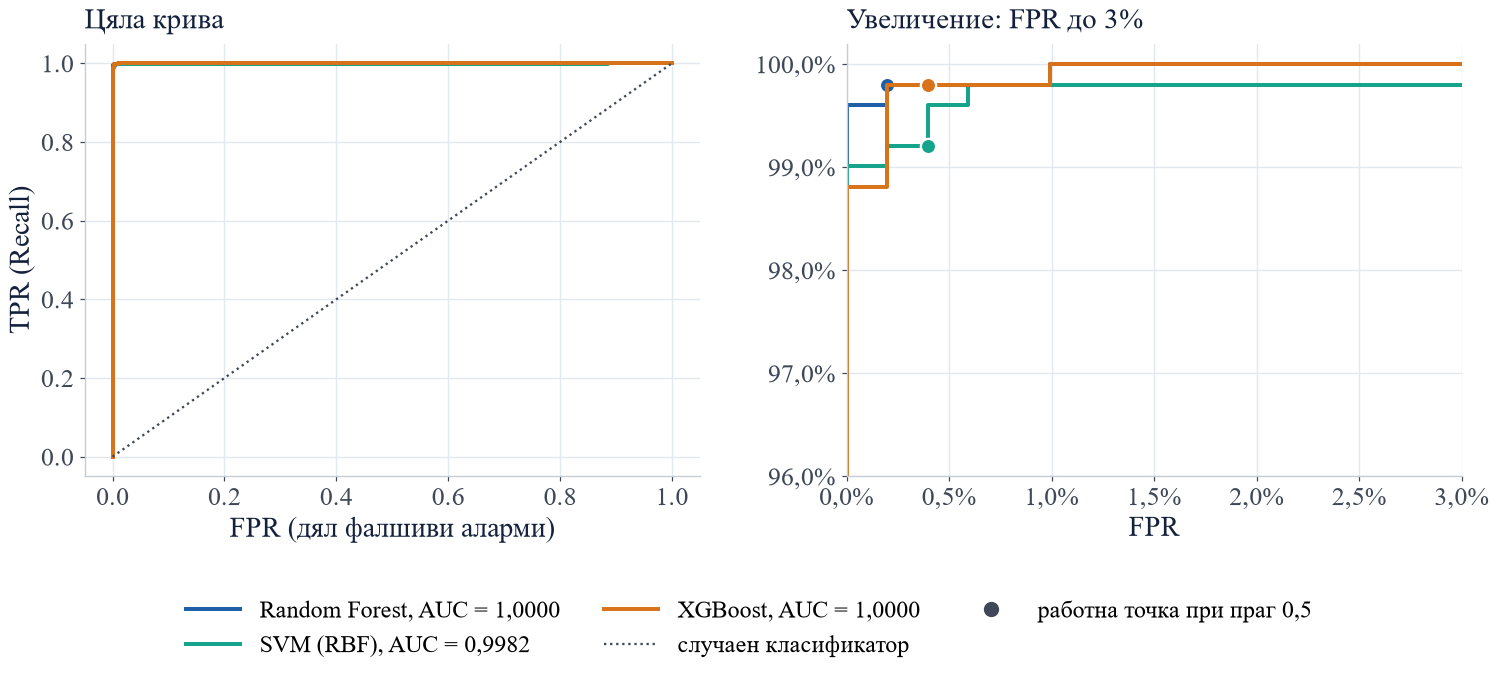

In [15]:
t = tasks[HARD]; yt = t["y_test"].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for g in ALG:
    sc_ = scores_of(models[(HARD, g)], t["X_test"])
    fpr, tpr, _ = roc_curve(yt, sc_)
    for ax in axes:
        ax.plot(fpr, tpr, color=ALGO_C[g], lw=2.6)
    r = MET[(HARD, g)]
    axes[1].plot(r.FPR, r.Sensitivity, "o", color=ALGO_C[g], ms=10, mec="white", mew=1.5)
axes[0].plot([0, 1], [0, 1], ":", color=MUTED); axes[0].set_xlabel("FPR (дял фалшиви аларми)"); axes[0].set_ylabel("TPR (Recall)")
axes[0].set_title("Цяла крива")
axes[1].set_xlim(0, 0.03); axes[1].set_ylim(0.96, 1.002); axes[1].xaxis.set_major_formatter(PCT(1)); axes[1].yaxis.set_major_formatter(PCT(1))
axes[1].set_xlabel("FPR"); axes[1].set_title("Увеличение: FPR до 3%")
fig.tight_layout(w_pad=2)
legend_below(fig, [Line2D([], [], color=ALGO_C[g], lw=2.6) for g in ALG] + [Line2D([], [], color=MUTED, ls=":"), Line2D([], [], color=MUTED, marker="o", ls="", ms=9)],
             [f"{ALGO_N[g]}, AUC = {MET[(HARD, g)].ROC_AUC:.4f}".replace(".", ",") for g in ALG] + ["случаен класификатор", "работна точка при праг 0,5"], ncol=3)
save(fig, "p14_roc")

## 6. Преобучение, доверителни интервали и тест на McNemar

### Диаграма 9. Точност при обучение, кръстосана валидация и тест

Ако модел е преобучен, точността върху обучаващите данни е видимо по-висока от тестовата. Под всеки модел е разликата между обучение и тест в процентни пунктове.

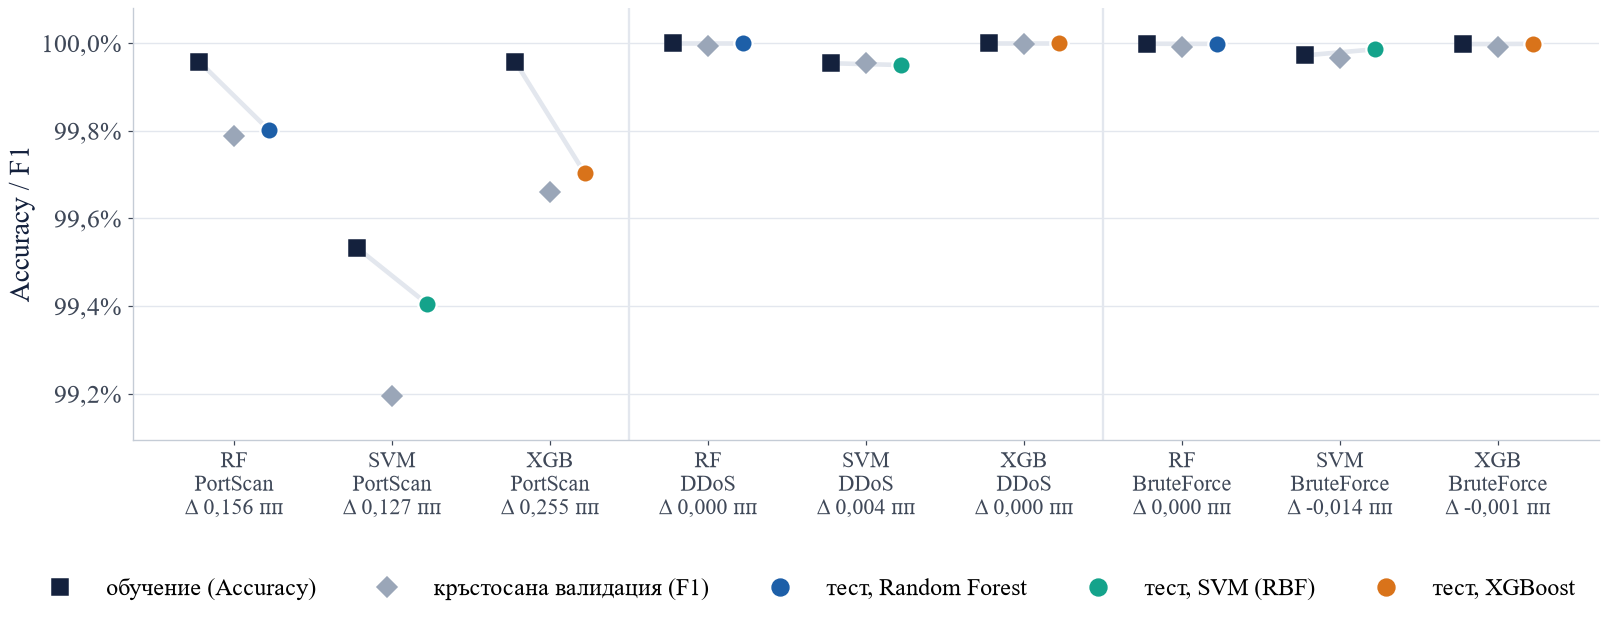

Максимална разлика обучение–тест: 0,255%


In [16]:
OF = pd.read_csv(RES / "overfitting.csv")
fig, ax = plt.subplots(figsize=(15, 5.2))
labels = []
for k, r in enumerate(OF.itertuples()):
    ax.plot([k - 0.22, k + 0.22], [r.train_accuracy, r.test_accuracy], color=GRID, lw=3, zorder=1)
    ax.plot(k - 0.22, r.train_accuracy, "s", color=INK, ms=10)
    ax.plot(k, r.cv_f1, "D", color="#9AA6B8", ms=9)
    ax.plot(k + 0.22, r.test_accuracy, "o", color=ALGO_C[r.algo], ms=12, mec="white", mew=1.5)
    labels.append(f"{r.algo}\n{ATT_N[r.attack]}\nΔ {r.gap_accuracy * 100:.3f} пп".replace(".", ","))
for k in (2.5, 5.5): ax.axvline(k, color=GRID, lw=1.5)
ax.set_xticks(range(len(OF)), labels, fontsize=14.5); ax.set_ylim(min(OF.train_accuracy.min(), OF.test_accuracy.min(), OF.cv_f1.min()) - 0.001, 1.0008); ax.yaxis.set_major_formatter(PCT(1))
ax.set_ylabel("Accuracy / F1"); ax.grid(axis="x", visible=False)
fig.tight_layout()
legend_below(fig, [Line2D([], [], color=INK, marker="s", ls="", ms=10), Line2D([], [], color="#9AA6B8", marker="D", ls="", ms=9)] +
             [Line2D([], [], color=ALGO_C[g], marker="o", ls="", ms=11) for g in ALG],
             ["обучение (Accuracy)", "кръстосана валидация (F1)"] + [f"тест, {ALGO_N[g]}" for g in ALG], ncol=5)
save(fig, "p13_overfitting")
print("Максимална разлика обучение–тест:", fmt_pct(OF.gap_accuracy.max(), 3))

### Диаграма 10. Bootstrap интервали и тест на McNemar

Вляво: 95% доверителни интервали на F1 при PortScan (1000 bootstrap извадки от тестовите записи). Вдясно: броят записи, на които само единият модел от двойката е прав, и p-стойността на теста на McNemar.

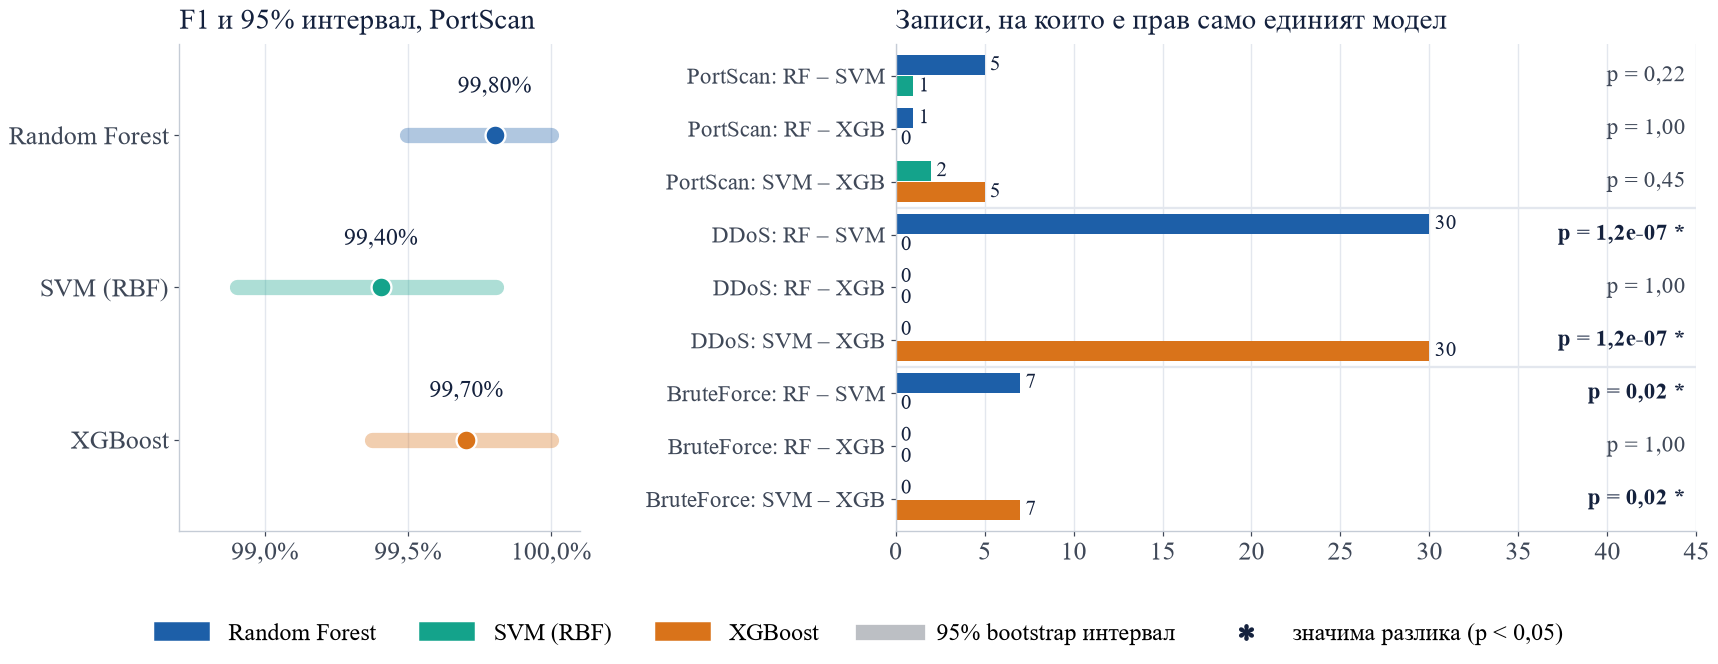

In [17]:
CI = pd.read_csv(RES / "bootstrap_ci.csv")
MC = json.load(open(RES / "mcnemar.json"))
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [0.75, 1.5]})
ax = axes[0]
for k, g in enumerate(ALG):
    r = CI[(CI.attack == HARD) & (CI.algo == g) & (CI.metric == "F1")].iloc[0]
    ax.plot([r.ci_low, r.ci_high], [k, k], color=ALGO_C[g], lw=10, alpha=0.35, solid_capstyle="round")
    ax.plot(r.value, k, "o", color=ALGO_C[g], ms=13, mec="white", mew=1.5)
    ax.text(r.value, k - 0.28, fmt_pct(r.value, 2), ha="center", fontsize=15.5, color=INK)
ax.set_yticks(range(3), [ALGO_N[g] for g in ALG]); ax.set_ylim(2.6, -0.6); ax.xaxis.set_major_formatter(PCT(1))
ax.set_xlim(CI[(CI.attack == HARD) & (CI.metric == "F1")].ci_low.min() - 0.002, 1.001); ax.set_title(f"F1 и 95% интервал, {HARD}"); ax.grid(axis="y", visible=False)
ax = axes[1]
rows = list(MC.values())
MX = max(max(m["only_A_correct"], m["only_B_correct"]) for m in rows)
for k, m in enumerate(rows):
    ax.barh(k - 0.2, m["only_A_correct"], height=0.38, color=ALGO_C[m["A"]])
    ax.barh(k + 0.2, m["only_B_correct"], height=0.38, color=ALGO_C[m["B"]])
    ax.text(m["only_A_correct"] + MX * 0.01, k - 0.2, str(m["only_A_correct"]), va="center", fontsize=14, color=INK)
    ax.text(m["only_B_correct"] + MX * 0.01, k + 0.2, str(m["only_B_correct"]), va="center", fontsize=14, color=INK)
    p = m["p_value"]; sig = p < 0.05
    ptxt = "p < 10⁻¹⁰" if p < 1e-10 else (f"p = {p:.1e}" if p < 0.001 else f"p = {p:.2f}").replace(".", ",")
    ax.text(MX * 1.48, k, ptxt + (" *" if sig else ""), va="center", ha="right", fontsize=15, color=INK if sig else MUTED, weight="bold" if sig else "normal")
ax.set_yticks(range(len(rows)), [f"{ATT_N[m['attack']]}: {m['A']} – {m['B']}" for m in rows], fontsize=15)
ax.set_ylim(len(rows) - 0.4, -0.6); ax.set_xlim(0, MX * 1.5)
ax.set_title("Записи, на които е прав само единият модел"); ax.grid(axis="y", visible=False)
for k in (2.5, 5.5): ax.axhline(k, color=GRID, lw=1.5)
fig.tight_layout(w_pad=2)
legend_below(fig, [Patch(color=ALGO_C[g]) for g in ALG] + [Line2D([], [], color=MUTED, lw=10, alpha=0.35), Line2D([], [], ls="", marker="$*$", color=INK, ms=10)],
             [ALGO_N[g] for g in ALG] + ["95% bootstrap интервал", "значима разлика (p < 0,05)"], ncol=5)
save(fig, "p16_mcnemar")

## 7. Контролни експерименти и анализи

### Диаграма 11. Контролни експерименти E1, E4 и E5

Точността на всеки модел в четири варианта на конвейера: основният (20 избрани признака), без редукция (E1), без времевите признаци (E4) и с PCA вместо подбор (E5). Цветът е разликата спрямо основния вариант.

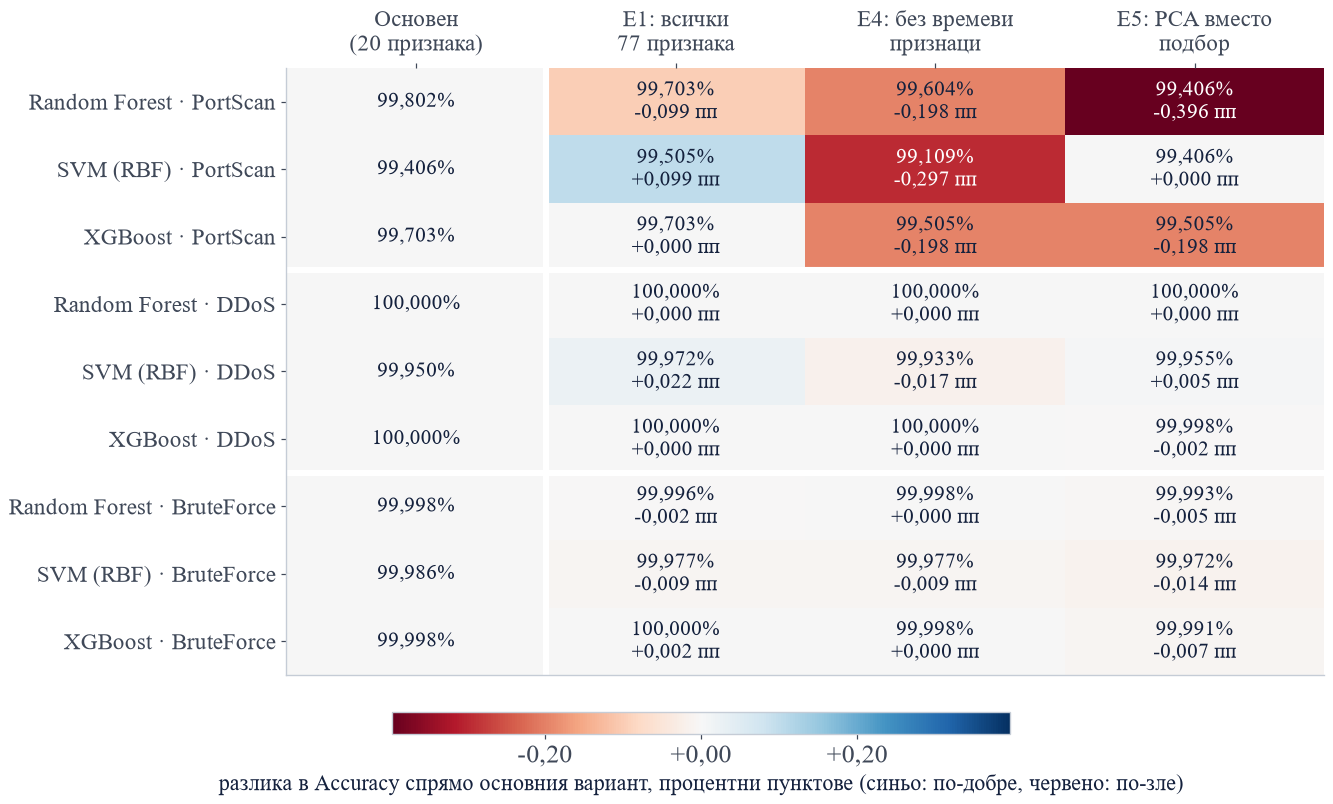

In [18]:
variants = [("Основен\n(20 признака)", "metrics.csv"), ("E1: всички\n77 признака", "metrics_full_features.csv"),
            ("E4: без времеви\nпризнаци", "metrics_without_IAT.csv"), ("E5: PCA вместо\nподбор", "metrics_other_reduction.csv")]
VT = {f: pd.read_csv(RES / f).set_index(["attack", "algo"]) for _, f in variants}
A_ = np.array([[VT[f].loc[k, "Accuracy"] for _, f in variants] for k in ROWS])
D_ = (A_ - A_[:, [0]]) * 100
fig, ax = plt.subplots(figsize=(12.5, 6.6))
lim = np.abs(D_).max()
im = ax.imshow(D_, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
for (i, j), v in np.ndenumerate(A_):
    dd = D_[i, j]
    txt = f"{v * 100:.3f}%".replace(".", ",") + ("" if j == 0 else f"\n{dd:+.3f} пп".replace(".", ","))
    ax.text(j, i, txt, ha="center", va="center", fontsize=14, color="white" if abs(dd) > lim * 0.6 else INK)
ax.set_xticks(range(4), [v for v, _ in variants], fontsize=15); ax.xaxis.tick_top()
ax.set_yticks(range(9), RLAB, fontsize=15); ax.grid(False)
for k in (2.5, 5.5): ax.axhline(k, color="white", lw=4)
ax.axvline(0.5, color="white", lw=4)
fig.tight_layout()
cax = fig.add_axes([0.3, -0.04, 0.45, 0.03])
cb = fig.colorbar(im, cax=cax, orientation="horizontal"); cb.ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.2f}".replace(".", ","))); cb.set_label("разлика в Accuracy спрямо основния вариант, процентни пунктове (синьо: по-добре, червено: по-зле)", fontsize=14.5)
save(fig, "p10_controls")

### Диаграма 12. Криви на обучение (A3)

F1 при обучение върху 1 000 до 100 000 записа (при PortScan: 1/8, 1/4, 1/2 и всички 2 354 обучаващи записа). Ансамблите от дървета достигат таван още при няколко хиляди записа; при PortScan и трите алгоритъма още печелят от повече данни.

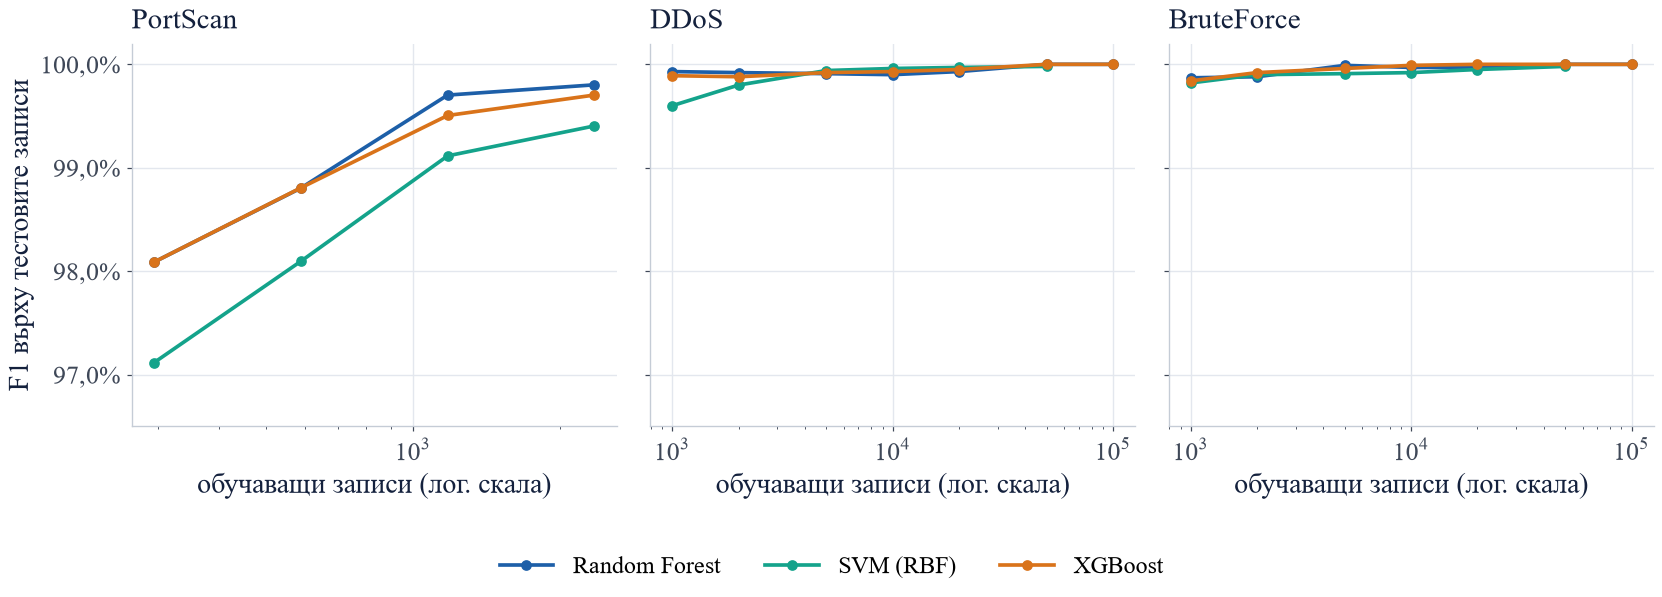

In [19]:
LC = pd.read_csv(RES / "learning_curves.csv")
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0), sharey=True)
for ax, a in zip(axes, ATT):
    for g in ALG:
        d = LC[(LC.attack == a) & (LC.algo == g)].sort_values("n_train")
        ax.plot(d.n_train, d.F1, "-o", color=ALGO_C[g], lw=2.4, ms=6)
    ax.set_xscale("log"); ax.xaxis.set_minor_formatter(NullFormatter()); ax.set_ylim(0.965, 1.002); ax.yaxis.set_major_formatter(PCT(1)); ax.set_title(ATT_N[a])
    ax.set_xlabel("обучаващи записи (лог. скала)")
axes[0].set_ylabel("F1 върху тестовите записи")
fig.tight_layout(w_pad=1.0)
legend_below(fig, [Line2D([], [], color=ALGO_C[g], marker="o", lw=2.4) for g in ALG], [ALGO_N[g] for g in ALG], ncol=3)
save(fig, "p17_learning_curves")

### Диаграма 13. Брой запазени измерения: подбор срещу PCA (A4)

F1 при PortScan спрямо броя запазени признаци (подбор) или компоненти (PCA). Хоризонталната линия е резултатът без редукция.

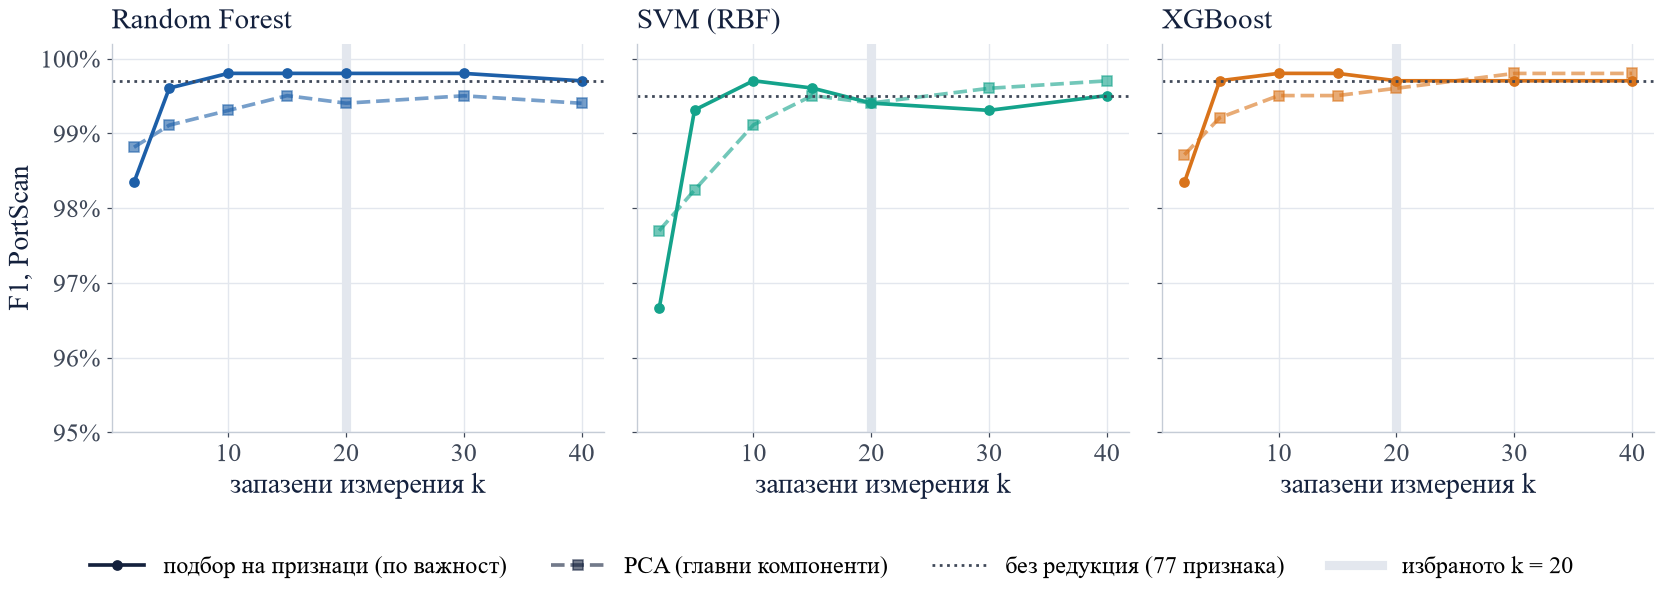

In [20]:
PS = pd.read_csv(RES / "pca_sweep.csv")
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0), sharey=True)
for ax, g in zip(axes, ALG):
    for meth, ls, mk, al in [("select", "-", "o", 1), ("pca", "--", "s", 0.6)]:
        d = PS[(PS.attack == HARD) & (PS.algo == g) & (PS.method == meth) & (PS.reduced)].sort_values("n_components")
        ax.plot(d.n_components, d.F1, ls=ls, marker=mk, color=ALGO_C[g], lw=2.4, ms=6, alpha=al)
    full = PS[(PS.attack == HARD) & (PS.algo == g) & (~PS.reduced)].F1.iloc[0]
    ax.axhline(full, color=MUTED, ls=":", lw=1.8)
    ax.axvline(20, color=GRID, lw=6, zorder=0)
    ax.set_ylim(0.95, 1.002); ax.yaxis.set_major_formatter(PCT(0)); ax.set_title(ALGO_N[g]); ax.set_xlabel("запазени измерения k")
axes[0].set_ylabel(f"F1, {HARD}")
fig.tight_layout(w_pad=1.0)
legend_below(fig, [Line2D([], [], color=INK, ls="-", marker="o", lw=2.4), Line2D([], [], color=INK, ls="--", marker="s", lw=2.4, alpha=0.6),
                   Line2D([], [], color=MUTED, ls=":", lw=1.8), Line2D([], [], color=GRID, lw=6)],
             ["подбор на признаци (по важност)", "PCA (главни компоненти)", "без редукция (77 признака)", "избраното k = 20"], ncol=4)
save(fig, "p18_pca_sweep")

### Диаграма 14. Естествено съотношение на класовете (E2)

Тестът се повтаря върху неизползвани записи в реалния дял на атаката (до 200 000; при PortScan са 3 613, защото уникалните записи на атаката са малко). Вляво: криви Precision–Recall за PortScan. Вдясно: брой грешки на 10 000 записа, отделно фалшиви аларми (FP) и пропуснати атаки (FN).

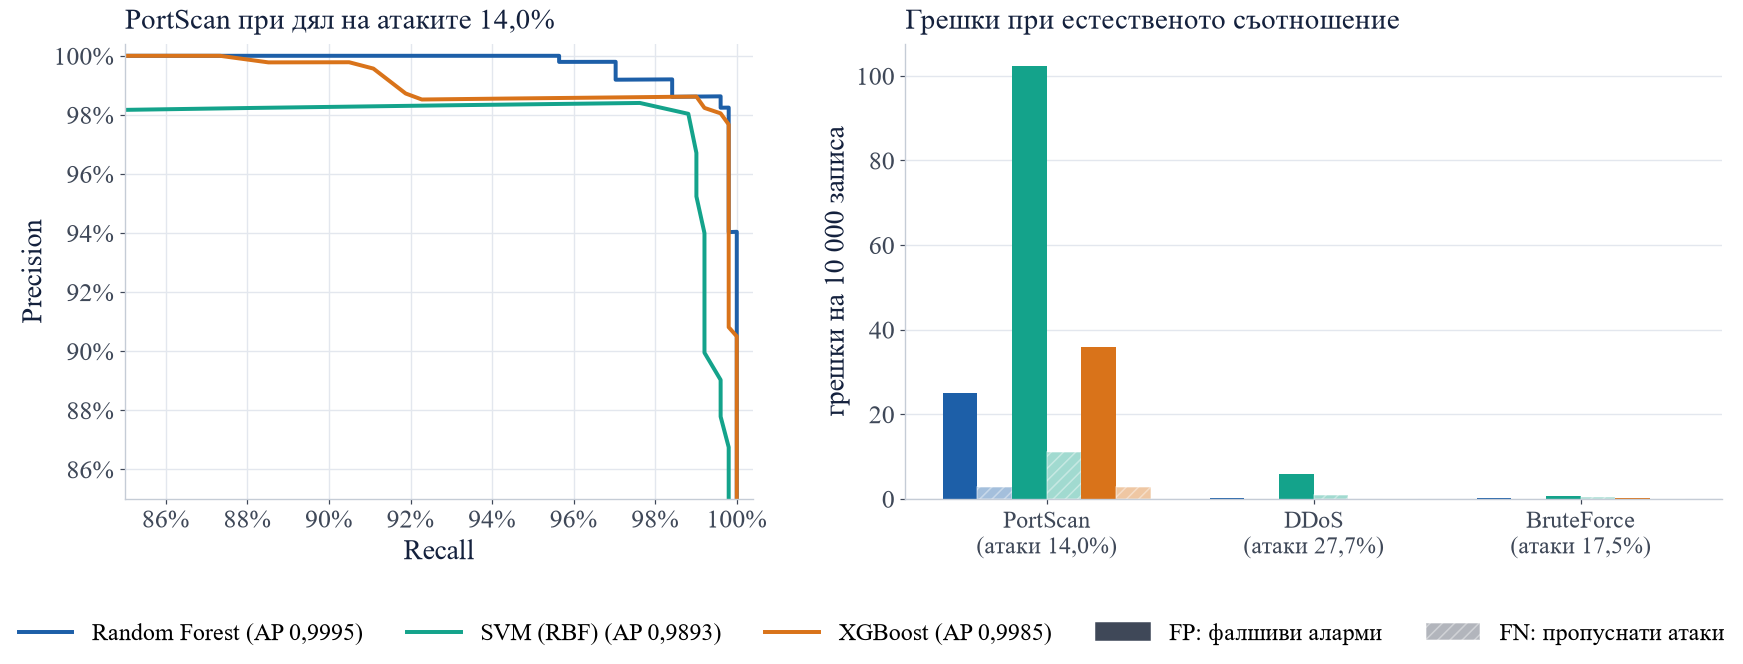

In [21]:
MN = pd.read_csv(RES / "metrics_natural_ratio.csv")
PR = json.load(open(RES / "pr_curves.json"))
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
for g in ALG:
    d = PR[f"{HARD}_{g}"]
    ax.plot(d["recall"], d["precision"], color=ALGO_C[g], lw=2.6)
ax.set_xlim(0.85, 1.004); ax.set_ylim(0.85, 1.004); ax.xaxis.set_major_formatter(PCT(0)); ax.yaxis.set_major_formatter(PCT(0))
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title(f"{HARD} при дял на атаките {fmt_pct(PR[f'{HARD}_RF']['base_rate'], 1)}")
ax = axes[1]
x = np.arange(3); w = 0.13
for j, g in enumerate(ALG):
    sub_ = MN[MN.algo == g].set_index("attack").loc[ATT]
    sc_ = 10_000 / sub_.n_test
    ax.bar(x + (2 * j - 2.5) * w, sub_.FP * sc_, width=w, color=ALGO_C[g])
    ax.bar(x + (2 * j - 1.5) * w, sub_.FN * sc_, width=w, color=ALGO_C[g], alpha=0.4, hatch="///", edgecolor="white")
ax.set_xticks(x, [f"{ATT_N[a]}\n(атаки {fmt_pct(MN[MN.attack == a].attack_share.iloc[0], 1)})" for a in ATT], fontsize=15.5)
ax.set_ylabel("грешки на 10 000 записа"); ax.set_title("Грешки при естественото съотношение"); ax.grid(axis="x", visible=False)
fig.tight_layout(w_pad=2)
legend_below(fig, [Line2D([], [], color=ALGO_C[g], lw=2.6) for g in ALG] + [Patch(color=MUTED), Patch(facecolor=MUTED, alpha=0.4, hatch="///", edgecolor="white")],
             [f"{ALGO_N[g]} (AP {PR[f'{HARD}_{g}']['average_precision']:.4f})".replace(".", ",") for g in ALG] + ["FP: фалшиви аларми", "FN: пропуснати атаки"], ncol=5)
save(fig, "p19_natural")

### Диаграма 15. Пермутационна важност (A8)

Спад на F1 при разбъркване на всеки признак в тестовите данни, за трите алгоритъма. Висока стойност означава, че моделът реално разчита на признака.

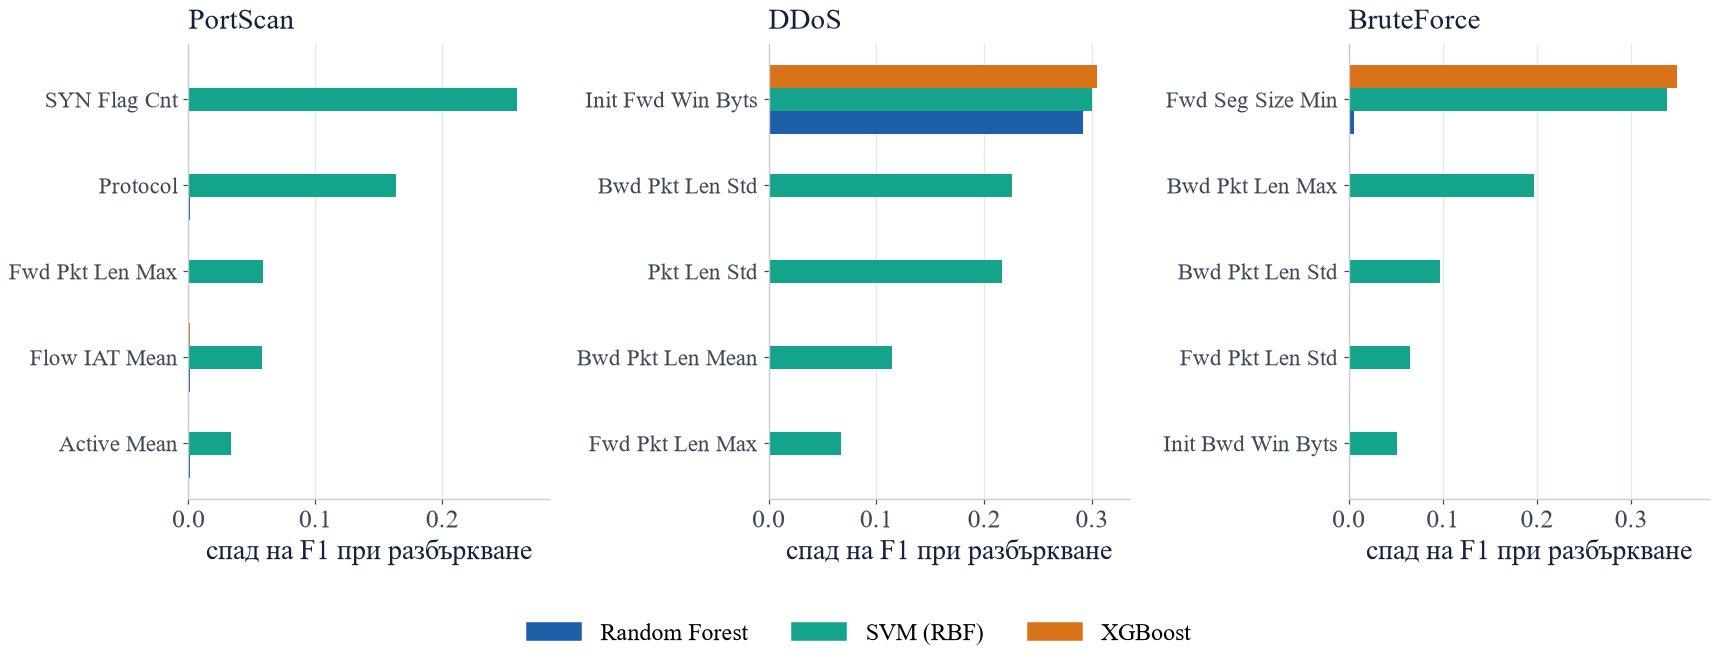

In [22]:
PI = pd.read_csv(RES / "permutation_importance.csv")
fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
for ax, a in zip(axes, ATT):
    d = PI[PI.attack == a]
    top = d.groupby("feature").importance_mean.max().nlargest(5).index[::-1]
    yy = np.arange(len(top))
    for j, g in enumerate(ALG):
        q = d[d.algo == g].set_index("feature").reindex(top).fillna(0)
        ax.barh(yy + (j - 1) * 0.27, q.importance_mean.clip(lower=0), height=0.27, color=ALGO_C[g])
    ax.set_yticks(yy, top, fontsize=15); ax.set_title(ATT_N[a]); ax.grid(axis="y", visible=False)
    ax.set_xlabel("спад на F1 при разбъркване")
    ax.set_xlim(0, d.importance_mean.max() * 1.1)
fig.tight_layout(w_pad=1.0)
legend_below(fig, [Patch(color=ALGO_C[g]) for g in ALG], [ALGO_N[g] for g in ALG], ncol=3)
save(fig, "p21_importance")

### Диаграма 16. Пренос между атаките (A7)

Модел, обучен за една атака (ред), се прилага към записите на друга атака (колона). Числото е делът открити атаки.

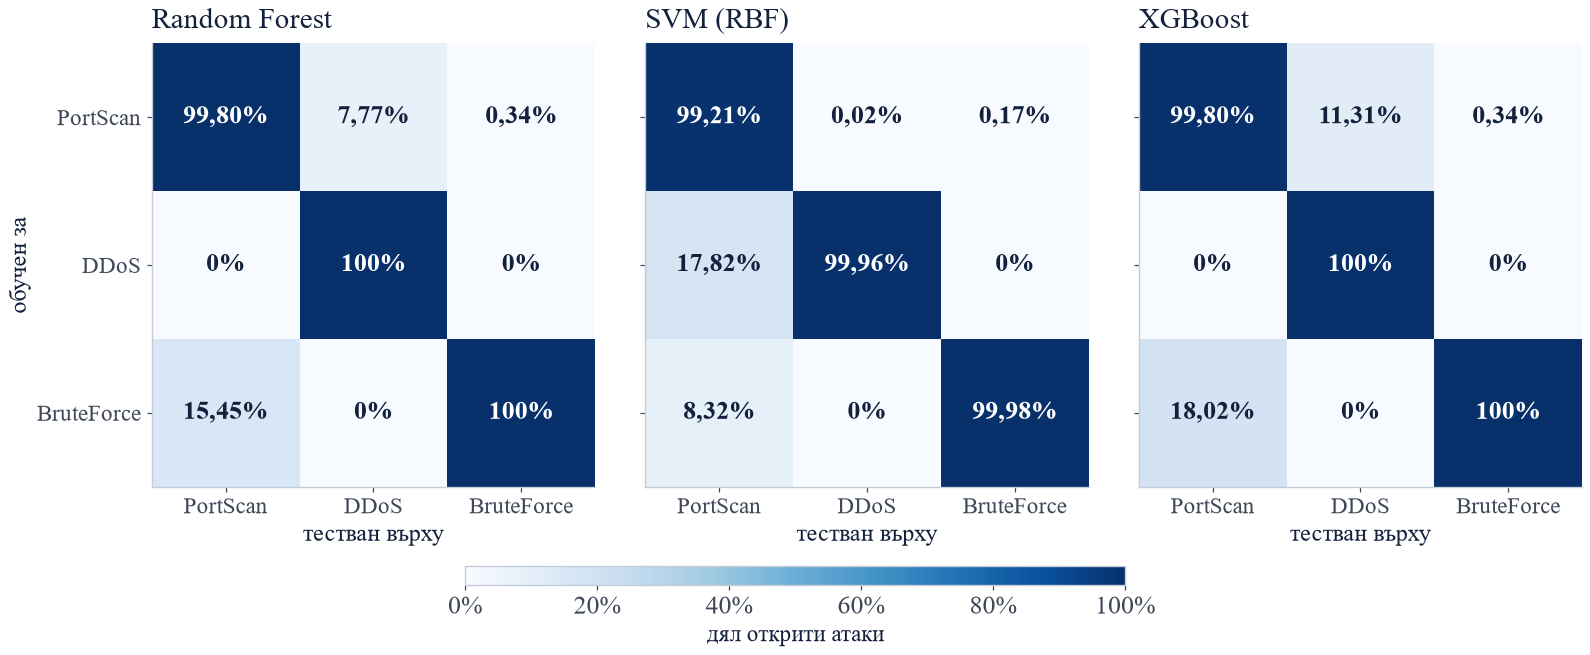

In [23]:
CA = pd.read_csv(RES / "cross_attack.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 5.0))
for ax, g in zip(axes, ALG):
    d = CA[CA.algo == g].pivot(index="train_attack", columns="test_attack", values="detection_rate").loc[ATT, ATT]
    im = ax.imshow(d.values, cmap="Blues", vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(d.values):
        ax.text(j, i, fmt_pct(v, 2 if 0 < v < 1 else 0), ha="center", va="center", fontsize=17, color="white" if v > 0.6 else INK, weight="bold")
    ax.set_xticks(range(3), [ATT_N[a] for a in ATT], fontsize=15); ax.set_yticks(range(3), [ATT_N[a] for a in ATT] if g == "RF" else [""] * 3, fontsize=15)
    ax.set_title(ALGO_N[g]); ax.grid(False); ax.set_xlabel("тестван върху", fontsize=15.5)
axes[0].set_ylabel("обучен за", fontsize=15.5)
fig.tight_layout(w_pad=1.0)
cax = fig.add_axes([0.3, -0.06, 0.4, 0.035])
cb = fig.colorbar(im, cax=cax, orientation="horizontal"); cb.ax.xaxis.set_major_formatter(PCT()); cb.set_label("дял открити атаки", fontsize=15)
save(fig, "p23_cross_attack")

### Диаграма 17. Скорост на класификация и време за обучение

Скоростта е броят записи в секунда в оперативната фаза (пакети по 10 000 записа). Времето за обучение е за финалния модел.

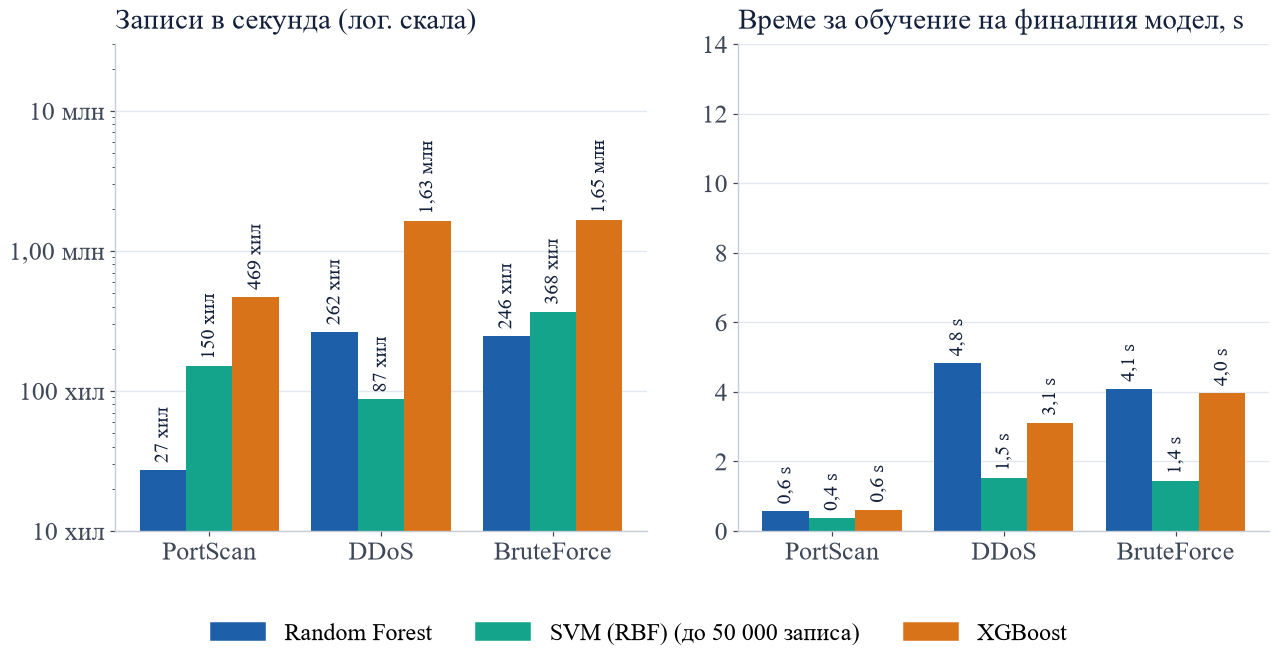

In [24]:
def short(n):
    return (f"{n / 1e6:.0f} млн" if n >= 9.5e6 else f"{n / 1e6:.2f} млн" if n >= 1e6 else f"{n / 1e3:.0f} хил").replace(".", ",")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
x = np.arange(3)
for k, g in enumerate(ALG):
    d = M[M.algo == g].set_index("attack").loc[ATT]
    sp_ = 1e6 / d.predict_time_per_record_us
    axes[0].bar(x + (k - 1) * 0.27, sp_, width=0.27, color=ALGO_C[g])
    axes[1].bar(x + (k - 1) * 0.27, d.fit_time_s, width=0.27, color=ALGO_C[g])
    for xx, v in zip(x + (k - 1) * 0.27, sp_):
        axes[0].text(xx, v * 1.12, short(v), ha="center", va="bottom", rotation=90, fontsize=13, color=INK)
    for xx, v in zip(x + (k - 1) * 0.27, d.fit_time_s):
        axes[1].text(xx, v + 0.2, f"{v:.1f} s".replace(".", ","), ha="center", va="bottom", rotation=90, fontsize=13, color=INK)
axes[0].set_yscale("log"); axes[0].set_ylim(1e4, 3e7); axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: short(v)))
axes[1].set_ylim(0, 14)
for ax, t_ in zip(axes, ["Записи в секунда (лог. скала)", "Време за обучение на финалния модел, s"]):
    ax.set_xticks(x, [ATT_N[a] for a in ATT]); ax.set_title(t_); ax.grid(axis="x", visible=False)
fig.tight_layout(w_pad=2)
legend_below(fig, [Patch(color=ALGO_C[g]) for g in ALG], [f"{ALGO_N[g]}" + (" (до 50 000 записа)" if g == "SVM" else "") for g in ALG], ncol=3)
save(fig, "p24_speed")

## 7б. Проверки за приложимост (A10–A14)

Основните резултати са почти перфектни, затова тук се проверява дали моделите разчитат на „отпечатъка“ на инструмента и на случайното разделяне. Резултатите са от `python -m src.robustness` (`results/robustness/`):

* **A10** – без признаците на TCP стека на изпращача (`Init Fwd Win Byts`, `Init Bwd Win Byts`, `Fwd Seg Size Min`);
* **A11** – хронологично разделяне: обучение върху по-ранните 70% от потоците в деня на атаката, тест върху по-късните 30%;
* **A12** – пренос между подвидове (HOIC ↔ LOIC-UDP, SSH ↔ FTP; PortScan няма подвидове);
* **A13** – фалшиви аларми върху нормалния трафик от други дни на същия набор;
* **A14** – комбиниран детектор: атака, ако XGBoost **или** SVM я открие.

В тези проверки нормалният трафик е от деня на атаката (освен в A13 б), затова числата за случайното разделяне леко се различават от основните.

In [25]:
ROB = RES / "robustness"
SF = pd.read_csv(ROB / "split_features.csv")
OD = pd.read_csv(ROB / "other_day_benign.csv")
LO = pd.read_csv(ROB / "held_out_day_benign.csv")
ST = pd.read_csv(ROB / "subtype_transfer.csv")
RMETA = json.loads((ROB / "meta.json").read_text(encoding="utf-8"))
ALG4 = ALG + ["XGB|SVM"]
ALGO_N4 = {**ALGO_N, "XGB|SVM": "XGBoost или SVM"}
ALGO_C4 = {**ALGO_C, "XGB|SVM": "#14213D"}
REPORT_FIG = RES / "figures"


def save_both(fig, name, report_name):
    fig.savefig(REPORT_FIG / f"{report_name}.png", facecolor="white")
    save(fig, name)


print(RMETA["benign_profile_by_day"])
print({k: v for k, v in RMETA.items() if k.endswith("chronological")})

{'Friday-02-03-2018': {'rows': 626486, 'init_win_65535_share': 0.0004213980839156821, 'tcp_share': 0.7379079500579422}, 'Friday-07-07-2017': {'rows': 271439, 'init_win_65535_share': 0.02018501394420109, 'tcp_share': 0.3641407461713313}, 'Monday-03-07-2017': {'rows': 339806, 'init_win_65535_share': 0.0948040941007516, 'tcp_share': 0.43212892061941227}, 'Wednesday-05-07-2017': {'rows': 282059, 'init_win_65535_share': 0.01865567133117539, 'tcp_share': 0.41043540535845335}, 'Wednesday-14-02-2018': {'rows': 485069, 'init_win_65535_share': 0.0025357217220642837, 'tcp_share': 0.7087754525644805}, 'Wednesday-21-02-2018': {'rows': 360774, 'init_win_65535_share': 0.9937689523080931, 'tcp_share': 0.99453397417774}}
{'PortScan_chronological': {'train_until': '17:55', 'test_from': '17:55', 'attack_test_from': '17:55', 'attack_train_until': '17:55', 'train_rows': 2356, 'test_rows': 1010, 'test_attack_labels': {'PortScan': 505}, 'train_attack_labels': {'PortScan': 1178}}, 'DDoS_chronological': {'trai

### Диаграма 18. Точност при четири постановки на теста (A10, A11, A14)

Редовете са моделите, колоните са постановките: случайно или хронологично разделяне, с всички признаци или без признаците-отпечатъци. Цветът е Accuracy; червеното показва най-голямото отклонение.

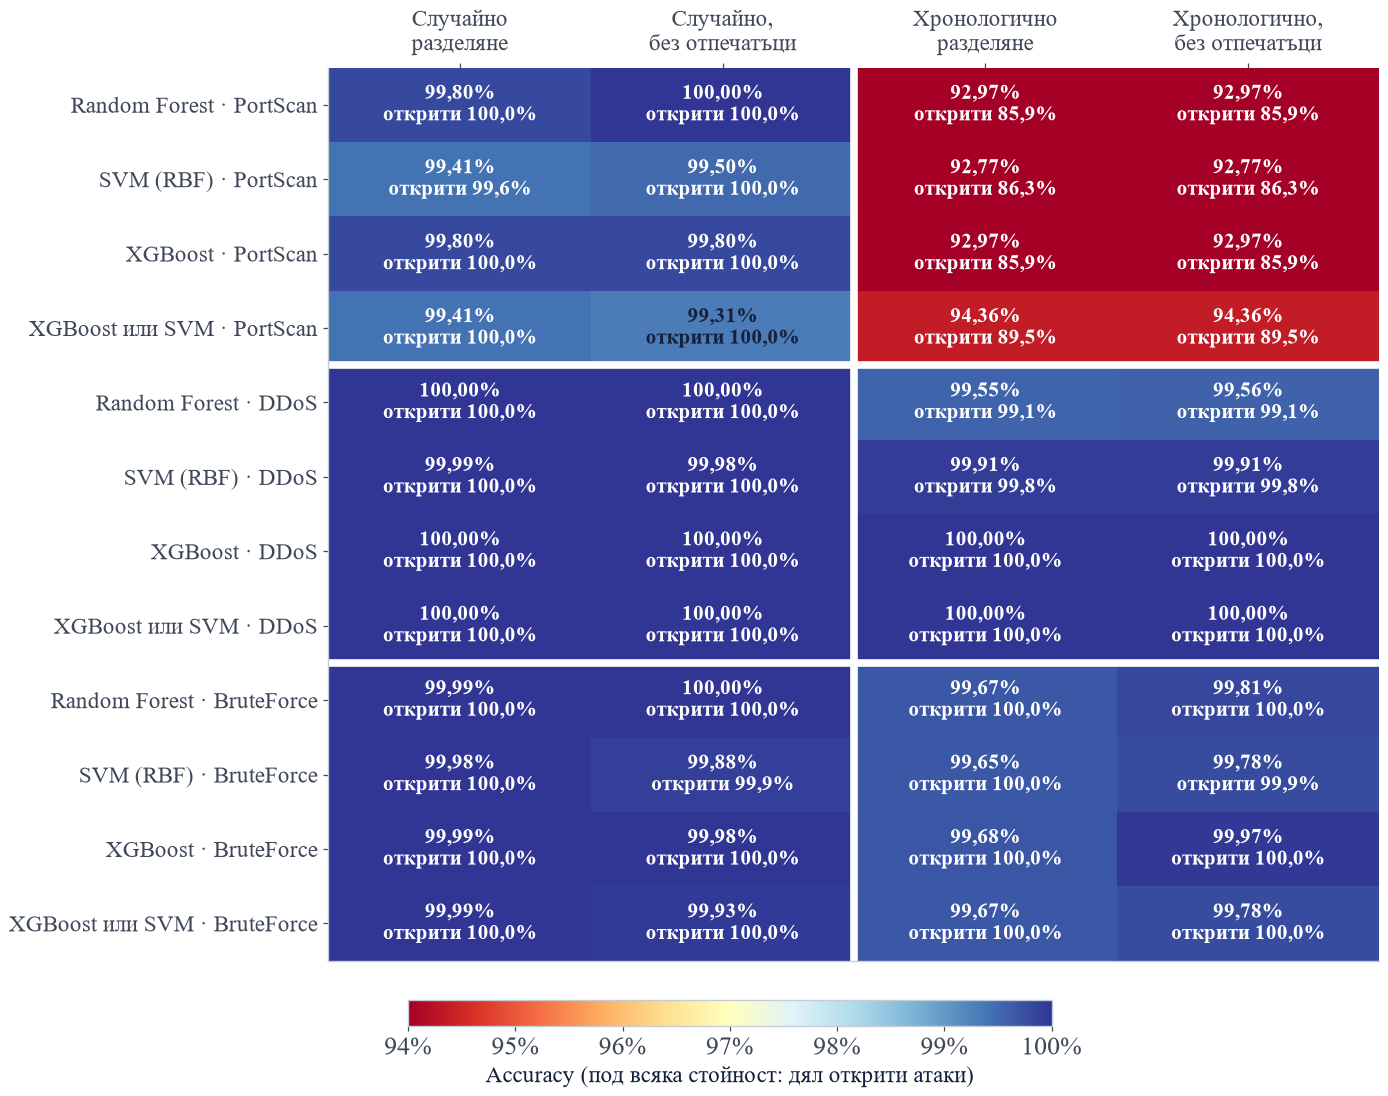

In [26]:
COLS = [("random", "all", "Случайно\nразделяне"), ("random", "no_fp", "Случайно,\nбез отпечатъци"),
        ("chronological", "all", "Хронологично\nразделяне"), ("chronological", "no_fp", "Хронологично,\nбез отпечатъци")]
R4 = [(a, g) for a in ATT for g in ALG4]
A4_ = np.array([[SF[(SF.attack == a) & (SF.algo == g) & (SF.split == s) & (SF.features == f)].Accuracy.iloc[0]
                 for s, f, _ in COLS] for a, g in R4])
S4_ = np.array([[SF[(SF.attack == a) & (SF.algo == g) & (SF.split == s) & (SF.features == f)].Sensitivity.iloc[0]
                 for s, f, _ in COLS] for a, g in R4])
fig, ax = plt.subplots(figsize=(13, 9.2))
im = ax.imshow(A4_, cmap="RdYlBu", vmin=0.94, vmax=1.0, aspect="auto")
for (i, j), v in np.ndenumerate(A4_):
    ax.text(j, i, f"{v * 100:.2f}%".replace(".", ",") + f"\nоткрити {S4_[i, j] * 100:.1f}%".replace(".", ","),
            ha="center", va="center", fontsize=13.5, color=INK if 0.962 < v < 0.9935 else "white", weight="bold")
ax.set_xticks(range(4), [c for *_, c in COLS], fontsize=15); ax.xaxis.tick_top()
ax.set_yticks(range(len(R4)), [f"{ALGO_N4[g]} · {ATT_N[a]}" for a, g in R4], fontsize=15); ax.grid(False)
for k in (3.5, 7.5): ax.axhline(k, color="white", lw=5)
ax.axvline(1.5, color="white", lw=5)
fig.tight_layout()
cax = fig.add_axes([0.3, -0.035, 0.45, 0.025])
cb = fig.colorbar(im, cax=cax, orientation="horizontal"); cb.ax.xaxis.set_major_formatter(PCT(0))
cb.set_label("Accuracy (под всяка стойност: дял открити атаки)", fontsize=15)
save_both(fig, "p25_robustness", "24_robustness_splits")

### Диаграма 19. Фалшиви аларми върху нормален трафик от непознат ден (A13)

Светлите стълбове са модели, обучени с нормален трафик само от деня на атаката; тъмните са обучени с нормален трафик от два дни. И в двата случая тестът е върху нормален трафик от ден, който моделът не е виждал. Скалата е логаритмична; „0“ означава нито една фалшива аларма на 100 000 записа.

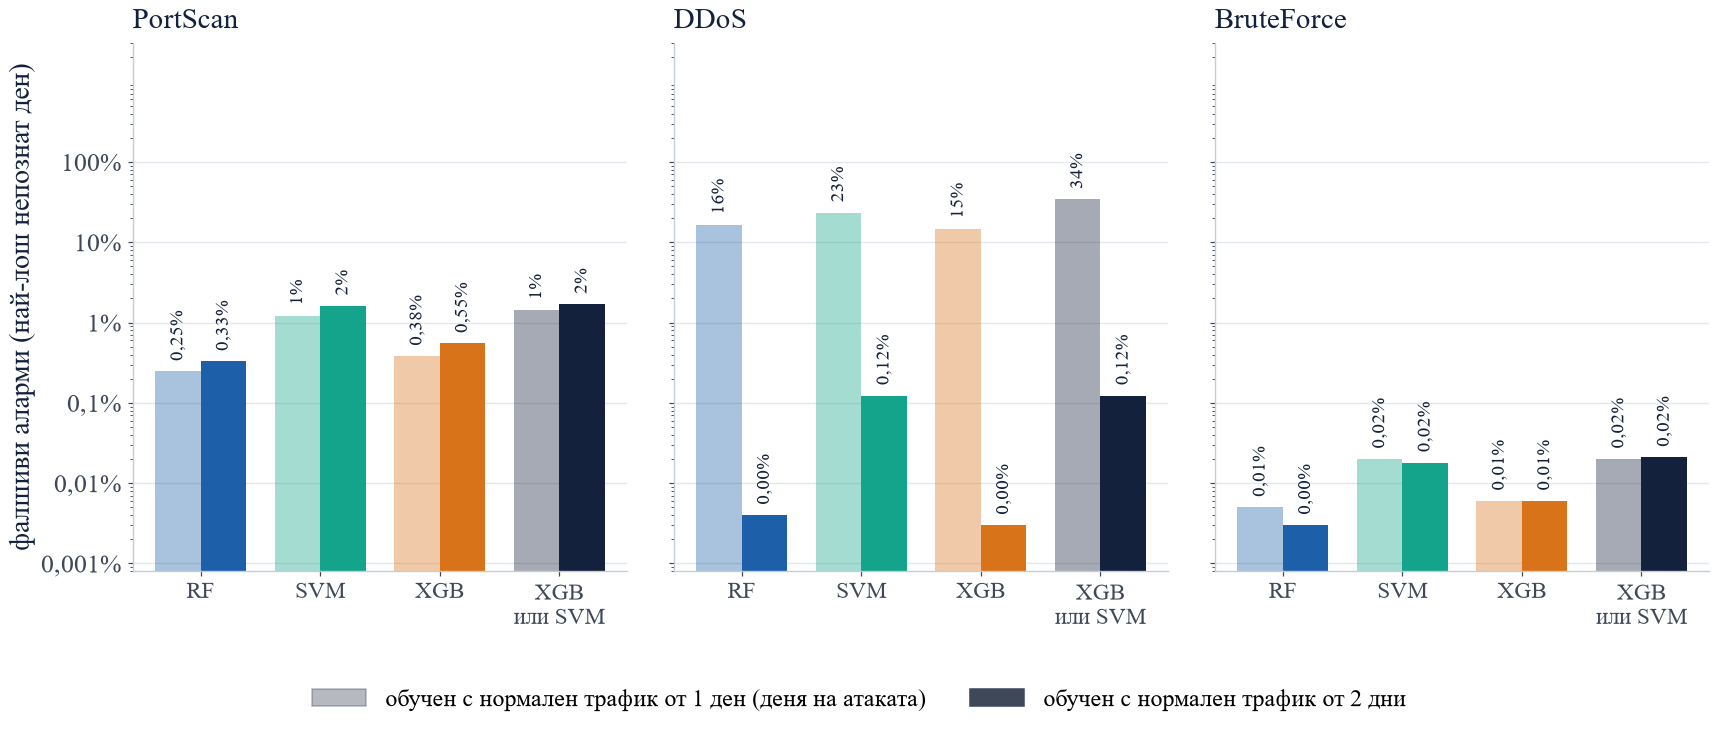

In [27]:
one = OD[OD.features == "all"].groupby(["attack", "algo"]).FPR.max()
two = LO.groupby(["attack", "algo"]).FPR_held_out.max()
FLOOR = 1e-5
fig, axes = plt.subplots(1, 3, figsize=(16, 6.2), sharey=True)
for ax, a in zip(axes, ATT):
    x = np.arange(len(ALG4))
    for k, (ser, alpha, lab) in enumerate([(one, 0.38, "1 ден"), (two, 1.0, "2 дни")]):
        vals = [ser.get((a, g), np.nan) for g in ALG4]
        ax.bar(x + (k - 0.5) * 0.38, [max(v, FLOOR) for v in vals], width=0.38,
               color=[ALGO_C4[g] for g in ALG4], alpha=alpha)
        for xx, v in zip(x + (k - 0.5) * 0.38, vals):
            t = "0" if v == 0 else (f"{v * 100:.0f}%" if v >= 0.01 else f"{v * 100:.2f}%").replace(".", ",")
            ax.text(xx, max(v, FLOOR) * 1.35, t, ha="center", va="bottom", fontsize=12.5, rotation=90, color=INK)
    ax.set_yscale("log"); ax.set_ylim(FLOOR * 0.8, 30)
    ax.set_xticks(x, ["RF", "SVM", "XGB", "XGB\nили SVM"], fontsize=15)
    ax.set_title(ATT_N[a]); ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: (f"{v * 100:g}%" if v < 1.01 else "").replace(".", ",")))
    ax.set_yticks([1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1])
axes[0].set_ylabel("фалшиви аларми (най-лош непознат ден)")
fig.tight_layout(w_pad=1.5)
legend_below(fig, [Patch(color=MUTED, alpha=0.38), Patch(color=MUTED)],
             ["обучен с нормален трафик от 1 ден (деня на атаката)", "обучен с нормален трафик от 2 дни"], ncol=2)
save_both(fig, "p26_benign_days", "25_benign_days")

### Диаграма 20. Пренос между подвидовете на атаката (A12)

Модел, обучен само върху единия инструмент, се прилага към записите на другия. Стойността е делът открити атаки от непознатия подвид.

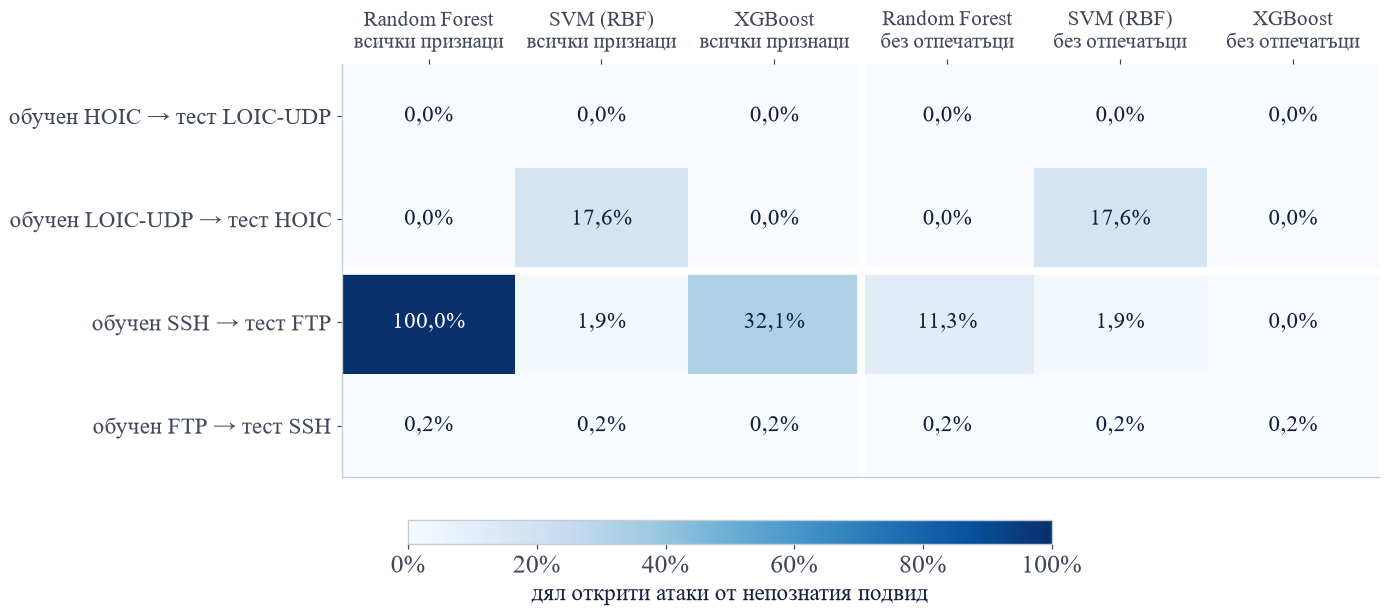

In [28]:
DIRS = [("DDOS attack-HOIC", "DDOS attack-LOIC-UDP"), ("DDOS attack-LOIC-UDP", "DDOS attack-HOIC"),
        ("SSH-Bruteforce", "FTP-BruteForce"), ("FTP-BruteForce", "SSH-Bruteforce")]
SN = {"DDOS attack-HOIC": "HOIC", "DDOS attack-LOIC-UDP": "LOIC-UDP", "SSH-Bruteforce": "SSH", "FTP-BruteForce": "FTP"}
CC = [(g, f) for f in ("all", "no_fp") for g in ALG]
M_ = np.array([[ST[(ST.train_on == s) & (ST.test_on == d) & (ST.algo == g) & (ST.features == f)].detected_other_subtype.iloc[0]
                for g, f in CC] for s, d in DIRS])
fig, ax = plt.subplots(figsize=(13, 4.8))
im = ax.imshow(M_, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for (i, j), v in np.ndenumerate(M_):
    ax.text(j, i, f"{v * 100:.1f}%".replace(".", ","), ha="center", va="center", fontsize=15, color="white" if v > 0.6 else INK)
ax.set_xticks(range(6), [f"{ALGO_N[g]}\n" + ("всички признаци" if f == "all" else "без отпечатъци") for g, f in CC], fontsize=13.5)
ax.xaxis.tick_top()
ax.set_yticks(range(4), [f"обучен {SN[s]} → тест {SN[d]}" for s, d in DIRS], fontsize=15); ax.grid(False)
ax.axvline(2.5, color="white", lw=5); ax.axhline(1.5, color="white", lw=5)
fig.tight_layout()
cax = fig.add_axes([0.3, -0.07, 0.45, 0.045])
cb = fig.colorbar(im, cax=cax, orientation="horizontal"); cb.ax.xaxis.set_major_formatter(PCT(0))
cb.set_label("дял открити атаки от непознатия подвид", fontsize=15)
save_both(fig, "p27_subtypes", "26_subtype_transfer")

## 8. Предварително изследване върху CICIoT2023 и сравнение с избраните набори

Първоначално изследването беше проведено върху IoT набора CICIoT2023 с атаките DDoS и Port Scan. Port Scan остана около 84% с всички алгоритми и подобрения, защото признаците на един прозорец от пакети не носят отпечатъка на Port Scan. Същата атака в CIC-IDS2017, описана с признаците на целия двупосочен поток, се открива с над 99%. Числата са от записаните резултати в `results/preliminary_ciciot2023/`.

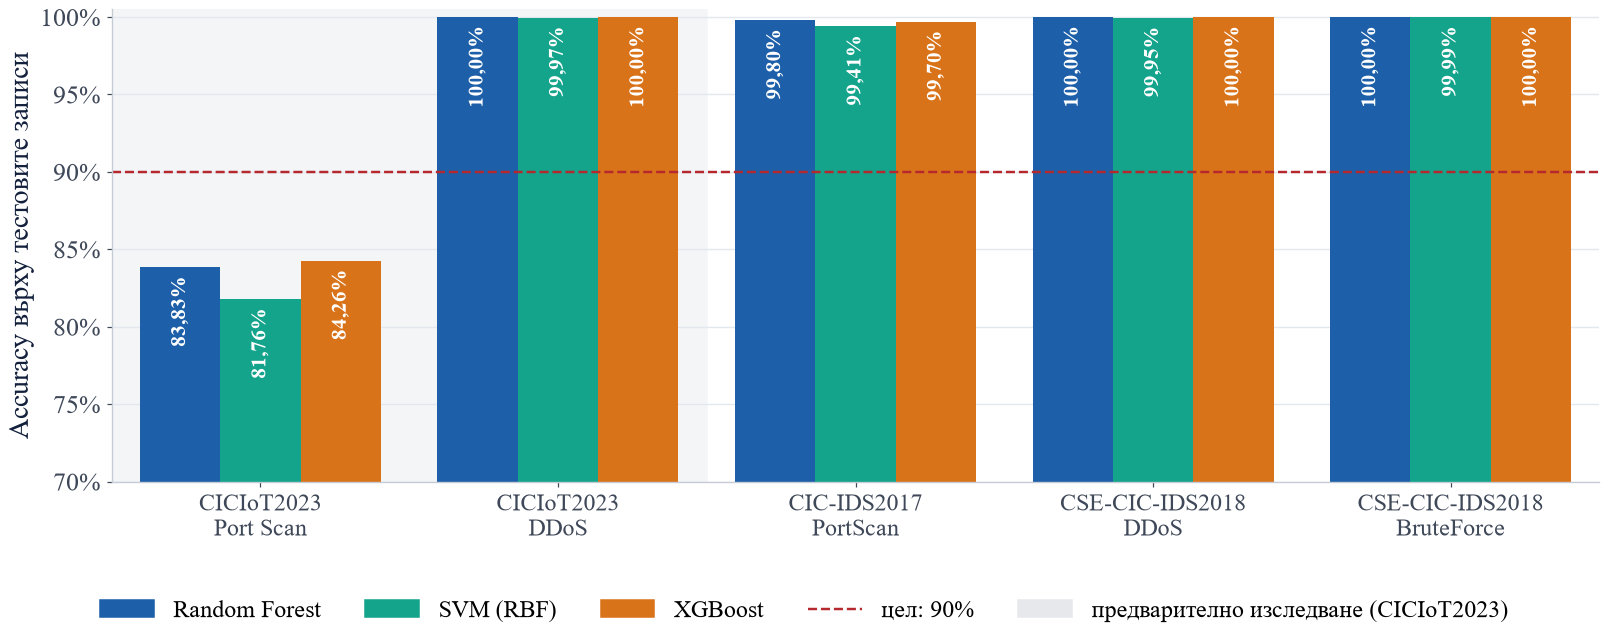

In [29]:
PRE = pd.read_csv(RES / "preliminary_ciciot2023" / "metrics.csv").set_index(["attack", "algo"])
fig, ax = plt.subplots(figsize=(15, 5.4))
rows = [("CICIoT2023\nPort Scan", [PRE.loc[("PortScan", g), "Accuracy"] for g in ALG]),
        ("CICIoT2023\nDDoS", [PRE.loc[("DDoS", g), "Accuracy"] for g in ALG])] + \
       [(f"{ATT_DS[a]}\n{ATT_N[a]}", [MET[(a, g)].Accuracy for g in ALG]) for a in ATT]
ax.axvspan(-0.5, 1.5, color="#F4F5F7", zorder=0)
for k, (nm, vals) in enumerate(rows):
    for j, g in enumerate(ALG):
        xx = k + (j - 1) * 0.27
        ax.bar(xx, vals[j], width=0.27, color=ALGO_C[g])
        ax.text(xx, vals[j] - 0.006, f"{vals[j] * 100:.2f}%".replace(".", ","), ha="center", va="top", rotation=90, fontsize=14, color="white", weight="bold")
ax.axhline(0.9, color="#B5282E", ls="--", lw=1.6)
ax.set_ylim(0.70, 1.005); ax.yaxis.set_major_formatter(PCT(0)); ax.set_xticks(range(len(rows)), [r[0] for r in rows], fontsize=15.5)
ax.set_xlim(-0.5, len(rows) - 0.5)
ax.set_ylabel("Accuracy върху тестовите записи"); ax.grid(axis="x", visible=False)
fig.tight_layout()
legend_below(fig, [Patch(color=ALGO_C[g]) for g in ALG] + [Line2D([], [], color="#B5282E", ls="--", lw=1.6), Patch(color="#E6E8EC")],
             [ALGO_N[g] for g in ALG] + ["цел: 90%", "предварително изследване (CICIoT2023)"], ncol=5)
save(fig, "p02_datasets")

### Изображение за титулната страница

Изображението е направено от реални записи: до 20 000 записа нормален трафик от двата набора, DDoS, BruteForce и PortScan, проектирани върху две главни компоненти.

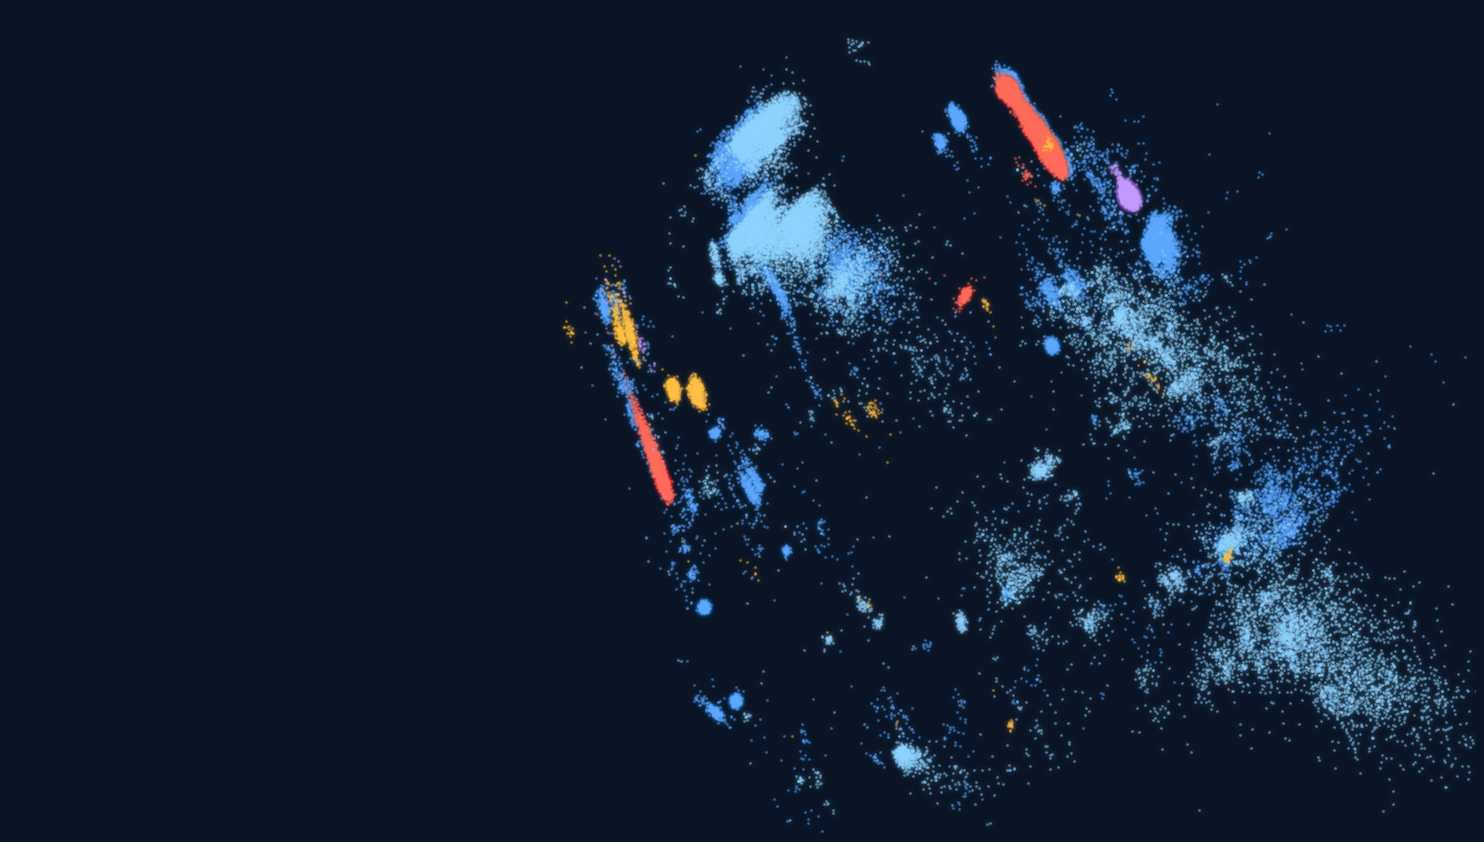

In [30]:
from sklearn.decomposition import PCA
Xs = df.iloc[samp_idx].drop(columns=[C.LABEL_COLUMN]).to_numpy(dtype=float)
Xs = np.log1p(np.abs(Xs)) * np.sign(Xs)
Xs = (Xs - Xs.mean(0)) / (Xs.std(0) + 1e-9)
Z = PCA(2, random_state=0).fit_transform(Xs)
gz = grp[samp_idx]
fig = plt.figure(figsize=(13.333, 7.5)); ax = fig.add_axes([0, 0, 1, 1]); fig.patch.set_facecolor("#0A1424"); ax.set_facecolor("#0A1424")
for g, c in [("Нормален", "#5FA8FF"), ("Нормален 2017", "#8FD3FF"), ("DDoS", "#FF6B5B"), ("BruteForce", "#C39BFF"), ("PortScan", "#FFC145")]:
    zz = Z[gz == g] + rng.normal(0, 0.06, (int((gz == g).sum()), 2))
    for s_, al in [(60, 0.012), (18, 0.03), (3, 0.5)]:
        ax.scatter(zz[:, 0], zz[:, 1], s=s_, color=c, alpha=al, linewidths=0)
lo, hi = np.quantile(Z, [0.003, 0.997], axis=0)
span = hi - lo
ax.set_xlim(lo[0] - span[0] * 0.75, hi[0] + span[0] * 0.08); ax.set_ylim(lo[1] - span[1] * 0.1, hi[1] + span[1] * 0.1)
ax.axis("off")
fig.savefig(FIG / "p00_title.png", dpi=180, facecolor=fig.get_facecolor(), bbox_inches=None, pad_inches=0)
plt.show(); plt.close(fig)

### Стойности за текста на слайдовете

Числата, които се цитират в текста на презентацията, се записват в `presentation/figures/values.json`, за да не се пренасят на ръка.

In [31]:
V = {"ks": {}, "median": {}, "pre": {}}
for a in ATT:
    top = KSdf[KSdf.attack == a].nlargest(10, "KS_D")
    V["ks"][a] = {"mean_top10": float(top.KS_D.mean()), "top": top.feature.tolist()[:5]}
for f in show:
    V["median"][f] = {g: float(S.loc[S["група"] == g, f].median()) for g in GROUPS}
for (a, g), r in PRE.iterrows():
    V["pre"][f"{a}_{g}"] = float(r.Accuracy)
V["dup_share"] = {k: float(1 - after[k] / orig[k]) for k in orig.index}
json.dump(V, open(FIG / "values.json", "w"), ensure_ascii=False, indent=1)
print(json.dumps(V["median"], ensure_ascii=False, indent=1))

{
 "Flow Duration": {
  "Нормален 2017": 93292.5,
  "PortScan": 596.0,
  "Нормален": 50662.5,
  "DDoS": 11839.0,
  "BruteForce": 374367.5
 },
 "Tot Fwd Pkts": {
  "Нормален 2017": 2.0,
  "PortScan": 2.0,
  "Нормален": 5.0,
  "DDoS": 3.0,
  "BruteForce": 22.0
 },
 "Flow Pkts/s": {
  "Нормален 2017": 44.163963317871094,
  "PortScan": 5571.03076171875,
  "Нормален": 80.3874740600586,
  "DDoS": 557.391357421875,
  "BruteForce": 117.82865905761719
 },
 "Init Fwd Win Byts": {
  "Нормален 2017": 0.0,
  "PortScan": 29200.0,
  "Нормален": 8192.0,
  "DDoS": 65535.0,
  "BruteForce": 26883.0
 }
}


### Списък на създадените диаграми

In [32]:
for p in sorted(FIG.glob("p*.png")):
    print(p.name)

p00_title.png
p01_class_counts.png
p02_datasets.png
p03_attack_profile.png
p04_ks_separability.png
p06_projection.png
p07_dimensions.png
p08_selection.png
p09_hp_RF.png
p09_hp_SVM.png
p09_hp_XGB.png
p09_one_se.png
p10_controls.png
p11_metrics.png
p12_confusion.png
p13_overfitting.png
p14_roc.png
p16_mcnemar.png
p17_learning_curves.png
p18_pca_sweep.png
p19_natural.png
p21_importance.png
p23_cross_attack.png
p24_speed.png
p25_robustness.png
p26_benign_days.png
p27_subtypes.png
